# Fashion-MNIST — 10 Specialist dan Generalist CNN: evaluasi lengkap serta Pareto Expansion

**Jalankan berurutan dari atas.** Notebook menggunakan CNN asli (bukan ResNet) serta 10 specialist biner dan 1 generalist multi-label (10 tugas). Eksperimen sekarang membandingkan:

1. **Baseline biasa** (loss BCE rata-rata, **tanpa** Pareto exploration maupun expansion).
2. **Pareto exploration saja**: PCGrad, MGDA, FAMO, dan checkpoint exploration terbaik menurut minimax BCE validasi.
3. **Pareto expansion**: MINRES, midpoint asli, midpoint + refinement MGDA, midpoint + refinement FAMO, dan **midpoint alpha efektif FAMO–MGDA + refinement MGDA**.

Setiap metode memilih checkpoint **hanya melalui validasi**. Pada setiap specialist dilaporkan accuracy, precision, recall, F1, balanced accuracy, specificity, ROC-AUC, average precision, TP/FP/TN/FN; untuk generalist diberikan metrik **multilabel** (exact-match, Hamming accuracy, micro/macro/weighted F1, dan per kelas) pada **validasi dan test**. Hasil diekspor ke CSV dan JSON pada `fashion_cnn_reports/` saat notebook dijalankan. Baris metode tanpa kandidat dilabeli *tidak tersedia*, tidak diganti dengan hasil metode lain.

**Skala alpha yang setara:** FAMO melakukan optimasi `sum(z_i * log(L_i+eps))/c`, dengan `z=softmax(w)` dan `c=sum(z_i/(L_i+eps))` diperlakukan konstan saat diferensiasi. Koefisien gradien efektifnya adalah `alpha_eff_i = (z_i/(L_i+eps)) / sum_j(z_j/(L_j+eps))`. Bobot efektif ini dan MGDA berada pada simplex (jumlah = 1) serta sama-sama merupakan koefisien gradien tiap objective. Eksperimen midpoint baru memakai `alpha_eff` FAMO **bukan** `softmax(w)` mentah; metode midpoint lama tetap dipertahankan sebagai ablation. Ini menyetarakan *makna koefisien gradien*, **bukan menjamin** keduanya setara secara performa atau menghasilkan titik Pareto global.

Proyeksi grafik 2D generalist **bukan** Pareto front 10D. Kebutuhan: PyTorch, torchvision, SciPy, NumPy, Matplotlib. Data Fashion-MNIST pertama kali perlu diunduh.


In [ ]:
# math menyediakan ceil dan log, random mengacak pergeseran dan urutan PCGrad, time mengukur durasi.
import math, random, time
# np mengolah array gambar dan label. torch menyediakan tensor, perangkat komputasi, dan gradien.
import numpy as np
import torch
# nn menyediakan lapisan jaringan. F menyediakan operasi padding, fungsi loss, dan softmax.
import torch.nn as nn
import torch.nn.functional as F
# plt menggambar hasil. datasets memuat Fashion-MNIST.
import matplotlib.pyplot as plt
from torchvision import datasets

In [ ]:
from copy import deepcopy
from collections import deque
from scipy.sparse.linalg import LinearOperator, minres
import inspect

In [ ]:
dev = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Perangkat:', dev)

Perangkat: cuda


In [ ]:
# Kesepuluh kelas diproses berurutan; model CNN agar training per kelas lebih ringan.
CFG = dict(
    SEED=0, BS=128, LR=0.001, EPOCHS=4, N_SPEC_HARD=2000,
    STEPS=60, MIDPOINT_REFINE_STEPS=60, ROUNDS=8, TARGET=0.015, WIDTH=0.02, PATIENCE=3,
    ALPHA_WINDOW=8, SECONDS=180, MINRES_ITERS=24,
    MINRES_BS=8, DAMP=0.1, STEP_SIZE=0.05,
    PLOT_SPECIALISTS=True,
    SAVE_TEACHERS=True,
    TEACHER_DIR='fashion_cnn_teachers',
    EVAL_THRESHOLD=0.5, REPORT_DIR='fashion_cnn_reports',
    PROGRESS_EVERY=100,   # Cetak batch training tiap 100 batch (0 untuk menonaktifkan).
)


In [ ]:
# set_seed menerima s dari SEED (ditambah indeks kelas untuk spesialis). Fungsi mengatur generator
# acak Python, NumPy dan PyTorch tanpa nilai balik.
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(s)
set_seed(CFG['SEED'])

## Data spesialis
Data latih mencakup gambar tunggal serta potongan pakaian dari tumpukan. Validasi memilih model. Data uji hanya dipakai setelah pilihan selesai.

In [ ]:
# CANVAS dan DS adalah ukuran sisi kanvas dan pakaian dalam piksel untuk penempatan, crop, padding, dan prep.
CANVAS, DS = 56, 28           # kanvas diperluas (sebelumnya 36), digit tetap 28x28 asli
# MAX_OVERLAP menjadi sasaran batas tumpang tindih saat mencari posisi di make_multi_flexible.
MAX_OVERLAP = 0.25            # maks. overlap kotak antar pakaian (fraksi luas 28x28)
# K_MIN dan K_MAX menentukan rentang jumlah pakaian per kanvas. K_MAX juga menentukan banyak slot label dan posisi.
K_MIN, K_MAX = 2, 4
# CLASS_NAMES memetakan indeks label Fashion-MNIST ke nama untuk laporan dan judul grafik.
CLASS_NAMES = ('T-shirt/top','Trouser','Pullover','Dress','Coat',
               'Sandal','Shirt','Sneaker','Bag','Ankle boot')

In [ ]:
# fashion_tr dan fashion_te adalah dataset asli dari torchvision. Atribut data dan targets dibaca di bawah.
fashion_tr = datasets.FashionMNIST('./data', train=True, download=True)
fashion_te = datasets.FashionMNIST('./data', train=False, download=True)
# all_tr_x/all_tr_y menyimpan gambar/label untuk pembagian latih-validasi. fa_te_x/fa_te_y untuk tumpukan dan evaluasi uji.
all_tr_x, all_tr_y = fashion_tr.data.numpy(), fashion_tr.targets.numpy()
fa_te_x, fa_te_y = fashion_te.data.numpy(), fashion_te.targets.numpy()

In [ ]:
# perm adalah urutan indeks acak dari SEED. Indeks yang sama menjaga pasangan gambar dan label saat dibagi.
perm = np.random.RandomState(CFG['SEED']).permutation(len(all_tr_x))
# fa_tr_x/fa_tr_y berisi 54.000 pasangan latih untuk gambar tunggal dan pembuatan tumpukan.
fa_tr_x, fa_tr_y = all_tr_x[perm[:54000]], all_tr_y[perm[:54000]]
# fa_val_x/fa_val_y adalah sisa pasangan dari perm untuk membuat tumpukan validasi.
fa_val_x, fa_val_y = all_tr_x[perm[54000:]], all_tr_y[perm[54000:]]

In [ ]:
# make_multi_flexible membuat n kanvas dari imgs dan labels milik bagian data yang dipilih pemanggil.
# k_min/k_max membatasi jumlah item, seed mengatur undian, max_overlap dan n_tries mengatur pencarian posisi.
# Hasilnya tiga array NumPy berurutan (gambar, ID kelas per slot, koordinat per slot), diterima keluarga Xg/Yg/Pg atau Xh_raw/Yh_raw/Ph_raw.
def make_multi_flexible(imgs, labels, n, k_min=K_MIN, k_max=K_MAX, seed=1,
                        max_overlap=MAX_OVERLAP, n_tries=30):
    # rng adalah generator lokal dari seed untuk mengundi jumlah, indeks, dan posisi pakaian.
    rng = np.random.RandomState(seed)
    # X menyimpan piksel tiap kanvas. Y menyimpan ID kelas dan P menyimpan (baris, kolom) tiap slot.
    # -1 menandai slot kosong.
    X = np.zeros((n, CANVAS, CANVAS), dtype=np.uint8)
    Y = np.full((n, k_max), -1, dtype=np.int64)
    P = np.full((n, k_max, 2), -1, dtype=np.int64)
    # off adalah koordinat awal terbesar agar pakaian tetap muat di kanvas.
    off = CANVAS - DS
    # i memilih kanvas keluaran. k_items adalah jumlah pakaian yang diundi untuk kanvas itu.
    for i in range(n):
        k_items = rng.randint(k_min, k_max + 1)
        # idx berisi indeks sumber dari imgs/labels. boxes mengingat posisi yang sudah ditempati pada kanvas i.
        idx = rng.randint(0, len(imgs), size=k_items)
        boxes = []
        # k adalah nomor slot keluaran, j indeks gambar asli dari idx untuk mengisi slot k.
        for k, j in enumerate(idx):
            # best dan best_ov menyimpan posisi dengan overlap terkecil beserta nilainya selama pencarian.
            best, best_ov = None, 9.0
            # _ menghitung percobaan sampai n_tries. py dan px adalah calon baris dan kolom kiri atas.
            for _ in range(n_tries):          # cari posisi dengan overlap kecil
                py, px = rng.randint(0, off + 1), rng.randint(0, off + 1)
                # by dan bx berasal dari boxes. ov adalah fraksi overlap terbesar calon posisi terhadap pakaian sebelumnya.
                ov = max([max(0, DS - abs(py - by)) * max(0, DS - abs(px - bx)) / (DS * DS)
                          for by,bx in boxes], default=0.0)
                if ov < best_ov:
                    best, best_ov = (py,px), ov
                if ov <= max_overlap:
                    break
            # py dan px mengambil posisi terbaik yang ditemukan, termasuk bila batas overlap belum tercapai.
            py, px = best
            boxes.append((py, px))
            # patch menjumlahkan piksel lama dan imgs[j] dalam 16 bit. Hasil dibatasi ke 255 untuk X,
            # lalu label dan posisi dicatat.
            patch = X[i, py:py+DS, px:px+DS].astype(np.uint16) + imgs[j].astype(np.uint16)
            X[i, py:py+DS, px:px+DS] = np.minimum(patch, 255).astype(np.uint8)
            Y[i, k] = labels[j]
            P[i, k] = [py, px]
    return X, Y, P

In [ ]:
# crop_pad menerima kanvas X, posisi P, dan nomor slot k dari pembuat data spesialis atau teacher_presence.
# Hasilnya array seukuran X berisi crop slot k di tengah kanvas hitam. Slot kosong menghasilkan kanvas hitam.
def crop_pad(X, P, k):
    # out menampung hasil crop. o adalah offset untuk menempatkannya di tengah.
    out = np.zeros_like(X)
    o = (CANVAS - DS) // 2
    # i memilih kanvas. y dan x berasal dari P[i,k] untuk menentukan area piksel sumber.
    for i in range(len(X)):
        if P[i, k, 0] != -1:
            y, x = P[i, k]
            out[i, o:o+DS, o:o+DS] = X[i, y:y+DS, x:x+DS]
    return out

In [ ]:
# pad_fashion menerima imgs dari fa_tr_x atau fa_te_x dan mengembalikan kanvas terpusat untuk Xs atau Xte_single.
def pad_fashion(imgs):
    # out adalah kanvas kosong per gambar, o adalah offset tempat menyalin imgs ke tengah.
    out = np.zeros((len(imgs), CANVAS, CANVAS), np.uint8)
    o = (CANVAS - DS) // 2
    out[:, o:o+DS, o:o+DS] = imgs
    return out

In [ ]:
# Data spesialis: gambar tunggal bersih + crop dari tumpukan, semuanya berlabel ASLI
# n_h menghitung jumlah kanvas sumber crop dari batas N_SPEC_HARD dan jumlah slot maksimum.
n_h = (CFG['N_SPEC_HARD'] + K_MAX - 1) // K_MAX
# Xh_raw/Yh_raw/Ph_raw adalah kanvas, kelas, dan posisi sintetis dari data latih untuk membuat contoh spesialis.
Xh_raw, Yh_raw, Ph_raw = make_multi_flexible(fa_tr_x, fa_tr_y, n_h, seed=4)
# Xs_h/Ys_h mula-mula daftar kumpulan crop/label per slot. k memilih slot, v menandai gambar yang memiliki slot itu.
Xs_h, Ys_h = [], []
for k in range(K_MAX):
    v = Ph_raw[:, k, 0] != -1
    Xs_h.append(crop_pad(Xh_raw, Ph_raw, k)[v]); 
    Ys_h.append(Yh_raw[v, k])
# Xs_h dan Ys_h kemudian menjadi array crop dan label yang digabung, dipotong sesuai batas, lalu dipasangkan dengan data bersih.
Xs_h = np.concatenate(Xs_h)[:CFG['N_SPEC_HARD']]
Ys_h = np.concatenate(Ys_h)[:CFG['N_SPEC_HARD']]
# Xs memasangkan kanvas bersih dan crop dalam satu array gambar. Ys menyusun label asli dalam urutan yang sama.
Xs = np.concatenate([pad_fashion(fa_tr_x), Xs_h])
Ys = np.concatenate([fa_tr_y, Ys_h])

In [ ]:
# Tensor disimpan di CPU. Hanya batch yang sedang diproses dipindahkan ke dev.
train = torch.from_numpy(Xs), torch.from_numpy(Ys)
valid = torch.from_numpy(pad_fashion(fa_val_x)), torch.from_numpy(fa_val_y)
test = torch.from_numpy(pad_fashion(fa_te_x)), torch.from_numpy(fa_te_y)
for c in range(len(CLASS_NAMES)):
    print('Spesialis:', CLASS_NAMES[c], '| Total gbr latih:', len(Ys), '| gbr kelas target:', np.sum(Ys == c), '| gbr kelas lainnya:', np.sum(Ys != c))


Spesialis: T-shirt/top | Total gbr latih: 55476 | gbr kelas target: 5518 | gbr kelas lainnya: 49958
Spesialis: Trouser | Total gbr latih: 55476 | gbr kelas target: 5556 | gbr kelas lainnya: 49920
Spesialis: Pullover | Total gbr latih: 55476 | gbr kelas target: 5561 | gbr kelas lainnya: 49915
Spesialis: Dress | Total gbr latih: 55476 | gbr kelas target: 5582 | gbr kelas lainnya: 49894
Spesialis: Coat | Total gbr latih: 55476 | gbr kelas target: 5541 | gbr kelas lainnya: 49935
Spesialis: Sandal | Total gbr latih: 55476 | gbr kelas target: 5555 | gbr kelas lainnya: 49921
Spesialis: Shirt | Total gbr latih: 55476 | gbr kelas target: 5533 | gbr kelas lainnya: 49943
Spesialis: Sneaker | Total gbr latih: 55476 | gbr kelas target: 5558 | gbr kelas lainnya: 49918
Spesialis: Bag | Total gbr latih: 55476 | gbr kelas target: 5528 | gbr kelas lainnya: 49948
Spesialis: Ankle boot | Total gbr latih: 55476 | gbr kelas target: 5544 | gbr kelas lainnya: 49932


In [ ]:
# 1 fungsiprep() menyiapkan gambar sebelum dimasukkan ke model. 
# 1 Gambar diubah ke format yang bisa dibaca model, lalu bisa digeser sedikit secara acak.
# 2 xb atau x-batch adalah sekumpulan gambar dalam bentuk tensor. 
# 2 Pada notebook ini, ukurannya (jumlah gambar, 56, 56). Setiap piksel biasanya bernilai dari 0 sampai 255.
# 3 shift adalah batas pergeseran acak dalam satuan piksel. Nilai awalnya 0, yang berarti gambar tidak digeser.   
# 4 Outputnya adalah tensor x yang siap masuk ke model. Ukurannya menjadi (jumlah gambar, 1, 56, 56). 
# 4 Angka 1 menunjukkan satu kanal warna karena gambar berwarna abu-abu. Nilai pikselnya sudah berada dalam rentang 0 sampai 1.
def prep(xb, shift=0): 
    # x berasal dari xb, dikonversi ke .float(), bagi .div(255), .unsqueeze(1) menambahkan dimensi kanal pada posisi ke-1
    x = xb.float().div(255).unsqueeze(1)
    if shift: 
        # sy dan sx adalah pergeseran acak vertikal/horizontal untuk seluruh batch. x dipad lalu dipotong kembali seukuran CANVAS.
        sy, sx = random.randint(-shift, shift), random.randint(-shift, shift) # cari int buat digeser
        x = F.pad(x, (shift,)*4) # padding biar ga kepotong pas digeser
        x = x[:, :, shift+sy:shift+sy+CANVAS, shift+sx:shift+sx+CANVAS] # baru deh dipotong
    return x # satu x-batch yang sudah digeser random sejauh shift

## Arsitektur CNN dan definisi multiobjective

- **Specialist (tiap kelas):** backbone CNN 1×56×56 → 32 fitur; **2 head**, masing-masing menghasilkan satu logit. Dua loss BCE: kelas target hadir, kelas target tidak hadir.
- **Generalis:** memakai backbone CNN yang sama, tetapi **10 head** dengan dua logit per kelas (hadir/tidak hadir). Output `(B,10,2)`.
- **Generalist multiobjective:** setiap head dihitung sebagai **satu tugas**, yaitu rata-rata BCE dua logit untuk satu kelas. Maka `head_losses` menghasilkan **10 loss**, sehingga MGDA, PCGrad, dan FAMO melibatkan 10 tujuan. MINRES/Alfa tengah juga memakai vektor alpha sepanjang 10.
- **Grafik generalis 2D:** hanya proyeksi rata-rata BCE *hadir vs tidak hadir* semua kelas; gunakan loss per kelas dan uji dominasi 10 dimensi untuk keputusan Pareto sebenarnya.


In [ ]:
class Specialist(nn.Module):
    def __init__(self):
        super().__init__()
        # CNN asli dari notebook; satu convolution, bukan ResNet-18.
        # Dari input 56x56: AvgPool -> 28x28 -> Conv stride 2 -> 12x12
        # -> AvgPool -> 6x6 -> Flatten(288) -> fitur dimensi 32.
        self.backbone = nn.Sequential(
            nn.AvgPool2d(2),
            nn.Conv2d(1, 8, kernel_size=5, stride=2),
            nn.Softplus(),
            nn.AvgPool2d(2),
            nn.Flatten(),
            nn.Linear(8 * 6 * 6, 32),
            nn.Softplus(),
        )
        self.heads = nn.ModuleList([
            nn.Linear(32, 1),
            nn.Linear(32, 1),
        ])

    def forward(self, x):
        features = self.backbone(x)
        return torch.cat([head(features) for head in self.heads], dim=1)


In [ ]:
def loss_components(model, batch, class_id=None):
    """(loss_tugas, proyeksi_2d). Generalist: 10 tugas, 2 sumbu hanya untuk plot."""
    images, labels = batch
    scores = model(prep(images.to(dev)))

    if labels.ndim == 2:
        # Generalist: 10 head x 2 logit, satu objektif per kelas.
        # Pembuatan target soft training dan label hard validasi/uji tetap sama.
        present = labels.to(device=dev, dtype=scores.dtype)
        assert scores.ndim == 3 and scores.shape[1:] == (len(CLASS_NAMES), 2)
        targets = torch.stack([present, 1.0 - present], dim=2)
        bce = F.binary_cross_entropy_with_logits(scores, targets, reduction='none')
        per_class = bce.mean(dim=(0, 2))    # (10,) -- objektif Pareto sesungguhnya
        projection_xy = bce.mean(dim=(0, 1)) # (2,) -- hanya proyeksi untuk grafik
        return per_class, projection_xy

    if class_id is None:
        raise ValueError('Specialist membutuhkan class_id eksplisit (0..9).')
    positive = labels.to(dev) == int(class_id)
    targets = torch.stack([positive, ~positive], dim=1).to(scores.dtype)
    bce = F.binary_cross_entropy_with_logits(scores, targets, reduction='none')
    objectives = bce.mean(dim=0)            # (2,) kelas target vs bukan target
    return objectives, objectives


def head_losses(model, batch, class_id=None):
    """Mengembalikan tensor objektif: (2,) Specialist atau (10,) Generalist."""
    return loss_components(model, batch, class_id=class_id)[0]


In [ ]:
@torch.no_grad()
def evaluate(model, data, class_id=None, return_components=False):
    """Evaluasi ber-batch: objektif asli dan proyeksi 2D, weighted by batch size.

    Secara default mengembalikan proyeksi 2D agar kode ringkasan lama tetap bisa
    memakai evaluate(...). Untuk memilih checkpoint gunakan return_components=True.
    """
    previous_mode = model.training
    model.eval()
    try:
        objective_sum = None
        projection_sum = torch.zeros(2, device=dev)
        n_total = 0
        for images, labels in zip(*(v.split(CFG['BS']) for v in data)):
            objectives, xy = loss_components(model, (images, labels), class_id)
            if objective_sum is None:
                objective_sum = torch.zeros_like(objectives)
            objective_sum += len(labels) * objectives
            projection_sum += len(labels) * xy
            n_total += len(labels)
        if n_total == 0:
            raise ValueError('Dataset evaluasi kosong.')
        objective_array = (objective_sum / n_total).cpu().numpy()
        xy_array = (projection_sum / n_total).cpu().numpy()
        return (objective_array, xy_array) if return_components else xy_array
    finally:
        model.train(previous_mode)


In [ ]:
# Tidak menambah dependency scikit-learn: metrik dihitung dari NumPy.
# AUC berdasarkan average ranks (memperhitungkan ties); AP = rata-rata presisi
# pada kenaikan recall untuk threshold unik (persis konsep average_precision).

def _safe_div(num, den):
    return float(num / den) if den else 0.0


def _binary_ranking_metrics(truth, probability):
    y = np.asarray(truth, dtype=bool)
    p = np.asarray(probability, dtype=np.float64)
    pos, neg = int(y.sum()), int((~y).sum())
    if not np.isfinite(p).all():
        raise ValueError('Probabilitas prediksi tidak finite.')
    if not pos or not neg:
        return float('nan'), float('nan') if not pos else 1.0
    # ROC-AUC = peluang skor positif lebih tinggi dari skor negatif, ties=0.5.
    order = np.argsort(p, kind='stable')
    sorted_p = p[order]
    ranks = np.empty(len(p), dtype=np.float64)
    ends = np.r_[np.flatnonzero(sorted_p[1:] != sorted_p[:-1]), len(p) - 1]
    begin = 0
    for end in ends:
        # average rank dengan indeks 1-based.
        ranks[order[begin:end+1]] = (begin + end + 2) / 2
        begin = end + 1
    auc = float((ranks[y].sum() - pos * (pos + 1) / 2) / (pos * neg))

    desc = np.argsort(-p, kind='stable')
    pp = p[desc]
    yy = y[desc]
    ends = np.r_[np.flatnonzero(pp[1:] != pp[:-1]), len(pp) - 1]
    tp_at = np.cumsum(yy)[ends]
    ap = float(np.sum((np.diff(np.r_[0, tp_at]) / pos) * (tp_at / (ends + 1))))
    return auc, ap


def _binary_metrics(truth, probability, threshold=0.5):
    y = np.asarray(truth, dtype=bool).reshape(-1)
    p = np.asarray(probability, dtype=np.float64).reshape(-1)
    pred = p >= threshold
    tp, tn = int(np.sum(pred & y)), int(np.sum(~pred & ~y))
    fp, fn = int(np.sum(pred & ~y)), int(np.sum(~pred & y))
    precision = _safe_div(tp, tp + fp)
    recall = _safe_div(tp, tp + fn)
    specificity = _safe_div(tn, tn + fp)
    f1 = _safe_div(2 * tp, 2 * tp + fp + fn)
    auc, ap = _binary_ranking_metrics(y, p)
    return dict(accuracy=_safe_div(tp + tn, len(y)), precision=precision,
                recall=recall, f1=f1, specificity=specificity,
                balanced_accuracy=(recall + specificity)/2,
                roc_auc=auc, average_precision=ap,
                tp=tp, tn=tn, fp=fp, fn=fn, support=int(y.sum()),
                n_samples=len(y))


@torch.no_grad()
def classification_metrics(model, data, class_id=None, threshold=None):
    """Metrik berdasar label HARD. Generalist: multilabel 10 kelas."""
    threshold = CFG['EVAL_THRESHOLD'] if threshold is None else threshold
    was_training = model.training
    model.eval()
    probs = []
    truths = []
    try:
        images_all, labels_all = data
        for start in range(0, len(labels_all), CFG['BS']):
            end = start + CFG['BS']
            logits = model(prep(images_all[start:end].to(dev)))
            if class_id is None:
                if labels_all.ndim != 2 or logits.shape[1:] != (len(CLASS_NAMES), 2):
                    raise ValueError('Generalist membutuhkan label multilabel (N,10).')
                prob = torch.sigmoid(logits[:, :, 0])
                true = labels_all[start:end]
                if not torch.all((true == 0) | (true == 1)):
                    raise ValueError('Gunakan label asli (hard), BUKAN soft target teacher, untuk evaluasi.')
            else:
                if labels_all.ndim != 1 or logits.shape[1] != 2:
                    raise ValueError('Specialist membutuhkan label ID kelas dan 2 output.')
                prob = torch.sigmoid(logits[:, 0])
                true = (labels_all[start:end] == int(class_id))
            probs.append(prob.detach().cpu().numpy())
            truths.append(true.detach().cpu().numpy())
    finally:
        model.train(was_training)
    if not probs:
        raise ValueError('Tidak dapat mengevaluasi dataset kosong.')
    probability = np.concatenate(probs)
    truth = np.concatenate(truths).astype(bool)
    if class_id is not None:
        metrics = _binary_metrics(truth, probability, threshold)
        metrics['class_name'] = CLASS_NAMES[class_id]
        return metrics

    predicted = probability >= threshold
    details = []
    for j, name in enumerate(CLASS_NAMES):
        detail = _binary_metrics(truth[:, j], probability[:, j], threshold)
        details.append(dict(class_id=j, class_name=name, **detail))
    tp = sum(d['tp'] for d in details)
    fp = sum(d['fp'] for d in details)
    fn = sum(d['fn'] for d in details)
    micro_precision = _safe_div(tp, tp + fp)
    micro_recall = _safe_div(tp, tp + fn)
    supports = np.array([d['support'] for d in details], dtype=float)
    result = dict(
        n_samples=len(truth),
        accuracy=float(np.mean(predicted == truth)),  # Hamming/label accuracy.
        exact_match_accuracy=float(np.mean(np.all(predicted == truth, axis=1))),
        hamming_loss=float(np.mean(predicted != truth)),
        precision=micro_precision, recall=micro_recall,
        f1=_safe_div(2 * tp, 2 * tp + fp + fn),
        precision_micro=micro_precision, recall_micro=micro_recall,
        f1_micro=_safe_div(2 * tp, 2 * tp + fp + fn),
        precision_macro=float(np.mean([d['precision'] for d in details])),
        recall_macro=float(np.mean([d['recall'] for d in details])),
        f1_macro=float(np.mean([d['f1'] for d in details])),
        precision_weighted=float(np.average([d['precision'] for d in details], weights=supports))
        if supports.sum() else 0.0,
        recall_weighted=float(np.average([d['recall'] for d in details], weights=supports))
        if supports.sum() else 0.0,
        f1_weighted=float(np.average([d['f1'] for d in details], weights=supports))
        if supports.sum() else 0.0,
        balanced_accuracy=float(np.mean([d['balanced_accuracy'] for d in details])),
        specificity=float(np.mean([d['specificity'] for d in details])),
        roc_auc=float(np.nanmean([d['roc_auc'] for d in details]))
        if any(np.isfinite(d['roc_auc']) for d in details) else float('nan'),
        average_precision=float(np.nanmean([d['average_precision'] for d in details]))
        if any(np.isfinite(d['average_precision']) for d in details) else float('nan'),
        tp=tp, fp=fp, fn=fn, tn=sum(d['tn'] for d in details),
        per_class=details,
    )
    # Macro-F1 tidak sama dengan micro-F1. Keduanya ditampilkan eksplisit.
    return result


def evaluate_method_groups(initial, groups, valid, test, class_id=None,
                           unavailable_reasons=None):
    """Pilih checkpoint TERBAIK di valid per metode, lalu hitung valid & test."""
    unavailable_reasons = unavailable_reasons or {}
    model = deepcopy(initial)
    rows = []
    for method, points, stage in groups:
        base = dict(method=method, stage=stage,
                    class_id=class_id if class_id is not None else -1,
                    class_name=CLASS_NAMES[class_id] if class_id is not None else 'Generalis',
                    n_candidates=len(points))
        if not points:
            rows.append(dict(**base, status='tidak tersedia',
                             reason=unavailable_reasons.get(method, 'Tidak ada kandidat')))
            continue
        best = min(points, key=lambda p: p['score'])
        model.load_state_dict(best['state'])
        vm = classification_metrics(model, valid, class_id=class_id)
        tm = classification_metrics(model, test, class_id=class_id)
        row = dict(**base, status='ok', reason='',
                   checkpoint_name=best['name'],
                   checkpoint_epoch=best.get('epoch', ''),
                   valid_minimax_bce=best['score'],
                   valid_objectives=best['objectives'].tolist(),
                   alpha_raw=None if best['alpha'] is None else best['alpha'].tolist(),
                   alpha_effective=None if alpha_for_comparison(best) is None
                                   else alpha_for_comparison(best).tolist())
        for split, metrics in (('valid', vm), ('test', tm)):
            for key, value in metrics.items():
                row[f'{split}_{key}'] = value
        rows.append(row)
    del model
    return rows


def print_comparison(rows, title='PERBANDINGAN'):
    print('\n' + title)
    print(f'{"Metode":53} {"Status":15} {"Acc test":>10} {"Prec":>9} {"Recall":>9} {"F1":>9} {"AUC":>9}')
    for row in rows:
        if row['status'] != 'ok':
            print(f"{row['method'][:53]:53} {row['status']:15} -- {row.get('reason','')}")
            continue
        print(f"{row['method'][:53]:53} {'ok':15} "
              f"{row['test_accuracy']:10.4f} {row['test_precision']:9.4f} "
              f"{row['test_recall']:9.4f} {row['test_f1']:9.4f} "
              f"{row['test_roc_auc']:9.4f}")
    if rows and rows[0]['class_id'] == -1:
        print('Generalist: Acc=Hamming accuracy, F1 di tabel=micro; F1 macro/weighted di CSV.')


def save_metrics_reports(prefix, rows):
    """File laporan otomatis disimpan ketika sel training benar-benar dieksekusi."""
    import csv, json
    from pathlib import Path
    folder = Path(CFG['REPORT_DIR'])
    folder.mkdir(parents=True, exist_ok=True)
    csv_path = folder / f'{prefix}_metrics.csv'
    json_path = folder / f'{prefix}_metrics.json'
    scalar_rows = []
    for row in rows:
        flat = {}
        for key, value in row.items():
            if isinstance(value, (list, dict, tuple)):
                continue  # Detail per kelas/alpha lengkap tersimpan di JSON.
            flat[key] = value
        scalar_rows.append(flat)
    columns = list(dict.fromkeys(key for row in scalar_rows for key in row.keys()))
    with csv_path.open('w', encoding='utf-8-sig', newline='') as handle:
        writer = csv.DictWriter(handle, fieldnames=columns)
        writer.writeheader()
        writer.writerows(scalar_rows)
    with json_path.open('w', encoding='utf-8') as handle:
        json.dump(rows, handle, indent=2, ensure_ascii=False, allow_nan=True)
    print('Laporan:', csv_path, 'dan', json_path)


In [ ]:
def flat_grads(losses, params):
    """Matriks gradien: satu baris per objektif, satu kolom per parameter."""
    params = tuple(params)  # aman jika pemanggil mengirim generator .parameters()
    gs = []
    for loss in losses:
        grads = torch.autograd.grad(
            loss, params, retain_graph=True, allow_unused=True
        )
        gs.append(torch.cat([
            (g if g is not None else torch.zeros_like(p)).reshape(-1)
            for g, p in zip(grads, params)
        ]))
    return torch.stack(gs, dim=0)


In [ ]:
# pcgrad menerima matriks gradien G dari flat_grads. Hasilnya vektor jumlah gradien setelah proyeksi, untuk g di train_step.
def pcgrad(G):
    # T adalah jumlah baris G. out menyalin G agar tiap baris dapat diperbarui.
    T = len(G); out = G.clone()
    # i memilih tugas yang dikoreksi, j memilih tugas pembanding secara acak.
    for i in range(T):
        for j in random.sample(range(T), T):
            if j == i: continue
            # dot mengukur keselarasan out[i] dan G[j]. Nilai negatif memicu pengurangan komponen yang bertentangan.
            dot = (out[i] * G[j]).sum()
            if dot < 0:
                out[i] = out[i] - dot / (G[j].norm() ** 2 + 1e-12) * G[j]
    return out.sum(0)

In [ ]:
# mgda_weights menerima G dari flat_grads dan batas iterasi iters. Hasilnya bobot a untuk kombinasi gradien a @ G.
def mgda_weights(G, iters=50):
    # M berisi hasil kali dalam antargradien. T jumlah tugas untuk menentukan ukuran a.
    M = G @ G.T; T = len(G)
    # a dimulai dengan bobot seragam, lalu diperbarui untuk memperkecil norma gradien gabungan.
    a = torch.ones(T, device=G.device) / T
    # _ menghitung iterasi. i memilih komponen terkecil dari M @ a sebagai arah menuju satu tugas.
    for _ in range(iters):
        i = torch.argmin(M @ a)
        # e memberi bobot satu pada tugas i. d adalah perubahan dari a menuju e, gamma menentukan panjang langkah sepanjang d.
        e = torch.zeros_like(a); 
        e[i] = 1
        d = e - a
        gamma = torch.clamp(-(d @ M @ a) / (d @ M @ d + 1e-12), 0, 1)
        a = a + gamma * d
    return a

In [ ]:
# FAMO: z_i = softmax(w)_i bukan koefisien kombinasi gradien.
# Koefisien gradien *efektif* = (z_i / (L_i + eps)) / sum_j (z_j / (L_j + eps)).
class FAMO:
    def __init__(self, T, lr=0.025, gamma=1e-3):
        self.w = torch.zeros(T, device=dev, requires_grad=True)
        self.opt = torch.optim.Adam([self.w], lr=lr, weight_decay=gamma)
        self.eps = 1e-8
        self.last_effective = None

    @torch.no_grad()
    def effective_weights(self, losses):
        z = F.softmax(self.w, dim=-1)
        weights = z / losses.detach().clamp_min(0).add(self.eps)
        return weights / weights.sum().clamp_min(1e-12)

    def weighted(self, losses):
        D = losses + self.eps
        z = F.softmax(self.w, dim=-1)
        # detach(c): gradien FAMO terhadap loss = alpha_eff @ gradien(loss).
        c = (z / D).sum().detach()
        return (D.log() * z / c).sum()

    def update(self, prev, curr):
        delta = (prev + self.eps).log() - (curr + self.eps).log()
        with torch.enable_grad():
            d = torch.autograd.grad(
                F.softmax(self.w, dim=-1), self.w,
                grad_outputs=delta.detach()
            )[0]
        self.opt.zero_grad(set_to_none=True)
        self.w.grad = d
        self.opt.step()


In [ ]:
def train_step(model, optimizer, batch, method, famo=None, alpha=None, class_id=None):
    """Satu langkah: 2 tugas specialist / 10 tugas generalist."""
    model.train()
    losses = head_losses(model, batch, class_id=class_id)
    optimizer.zero_grad(set_to_none=True)

    if method in ('MGDA', 'PCGrad'):
        shared = list(model.backbone.parameters())
        G = flat_grads(losses, shared)
        if method == 'MGDA':
            alpha = mgda_weights(G).detach()
            combined = alpha @ G
            # Head dan backbone memakai alpha yang konsisten (seperti FAMO).
            (alpha @ losses).backward()
        else:
            combined = pcgrad(G) / len(losses)
            losses.mean().backward()  # PCGrad: head menggunakan BCE rata-rata.
        offset = 0
        for param in shared:
            size = param.numel()
            param.grad = combined[offset:offset + size].view_as(param).clone()
            offset += size
    elif method == 'FAMO':
        if famo is None:
            raise ValueError('Metode FAMO membutuhkan state FAMO.')
        alpha = F.softmax(famo.w.detach(), dim=0)  # alpha MENTAH / z, untuk ablation.
        famo.last_effective = famo.effective_weights(losses).detach().cpu().numpy()
        famo.weighted(losses).backward()
        model.eval()
        with torch.no_grad():
            before = head_losses(model, batch, class_id=class_id)
    else:
        if alpha is None or alpha.numel() != losses.numel():
            raise ValueError(f'Metode weighted sum membutuhkan {len(losses)} bobot alpha.')
        (alpha @ losses).backward()

    optimizer.step()
    if method == 'FAMO':
        with torch.no_grad():
            after = head_losses(model, batch, class_id=class_id)
        famo.update(before, after)
        model.train()
    return None if alpha is None else alpha.detach().cpu().numpy()


In [ ]:
def _normalize_alpha(alpha):
    if alpha is None:
        return None
    a = np.asarray(alpha, dtype=np.float32).copy()
    if a.ndim != 1 or not np.isfinite(a).all() or np.any(a < 0):
        raise ValueError('Alpha harus vektor finite non-negatif.')
    total = float(a.sum())
    if total <= 0:
        raise ValueError('Jumlah bobot alpha harus positif.')
    return a / total


def checkpoint(model, name, alpha=None, valid=valid, class_id=None,
               alpha_effective=None):
    """Snapshot validasi; simpan alpha mentah DAN koefisien gradien efektif."""
    objectives, xy = evaluate(model, valid, class_id=class_id, return_components=True)
    raw = _normalize_alpha(alpha)
    eff = _normalize_alpha(alpha_effective if alpha_effective is not None else raw)
    return dict(
        name=name, xy=xy, objectives=objectives,
        score=float(np.max(objectives)), alpha=raw, alpha_effective=eff,
        state={k: v.detach().cpu().clone() for k, v in model.state_dict().items()},
    )


In [ ]:
def explore(initial, method, train=train, valid=valid, class_id=None):
    """Exploration independent dari inisialisasi serupa; FAMO menyimpan dua alpha."""
    seed = CFG['SEED'] + (class_id if class_id is not None else 0)
    set_seed(seed)
    model = deepcopy(initial)
    optimizer = torch.optim.AdamW(model.parameters(), lr=CFG['LR'])
    n_tasks = len(CLASS_NAMES) if class_id is None else 2
    famo = FAMO(n_tasks) if method == 'FAMO' else None
    history = []
    label = 'Generalis' if class_id is None else CLASS_NAMES[class_id]
    for epoch in range(CFG['EPOCHS']):
        start_epoch = time.perf_counter()
        recent_raw = deque(maxlen=CFG['ALPHA_WINDOW'])
        recent_effective = deque(maxlen=CFG['ALPHA_WINDOW'])
        batches = torch.randperm(len(train[1])).split(CFG['BS'])
        print(f'[{label}] {method} epoch {epoch + 1}/{CFG["EPOCHS"]} ({len(batches)} batch)', flush=True)
        for batch_no, ids in enumerate(batches, 1):
            raw = train_step(
                model, optimizer, (train[0][ids], train[1][ids]),
                method, famo=famo, class_id=class_id,
            )
            if raw is not None:
                recent_raw.append(raw)
                recent_effective.append(
                    famo.last_effective.copy() if famo is not None else raw
                )
            progress = CFG['PROGRESS_EVERY']
            if progress and (batch_no % progress == 0 or batch_no == len(batches)):
                print(f'    batch {batch_no}/{len(batches)} | {time.perf_counter()-start_epoch:.1f}s', flush=True)
        cp = checkpoint(
            model, method, np.mean(recent_raw, axis=0) if recent_raw else None,
            valid=valid, class_id=class_id,
            alpha_effective=np.mean(recent_effective, axis=0)
            if recent_effective else None,
        )
        cp['epoch'] = epoch + 1
        history.append(cp)
        print(f'    selesai epoch {epoch + 1}: minimax valid={cp["score"]:.5f}', flush=True)
    return history


def train_standard_baseline(initial, train=train, valid=valid, class_id=None):
    """Kontrol tanpa Pareto: BCE rata-rata, EPOCHS/LR/BS/inisialisasi sama."""
    set_seed(CFG['SEED'] + (class_id if class_id is not None else 0))
    model = deepcopy(initial)
    optimizer = torch.optim.AdamW(model.parameters(), lr=CFG['LR'])
    history = []
    for epoch in range(CFG['EPOCHS']):
        model.train()
        batches = torch.randperm(len(train[1])).split(CFG['BS'])
        for i, ids in enumerate(batches, 1):
            optimizer.zero_grad(set_to_none=True)
            head_losses(model, (train[0][ids], train[1][ids]),
                        class_id=class_id).mean().backward()
            optimizer.step()
            progress = CFG['PROGRESS_EVERY']
            if progress and (i % progress == 0 or i == len(batches)):
                print(f'    [Baseline] epoch {epoch+1}/{CFG["EPOCHS"]} batch {i}/{len(batches)}', flush=True)
        cp = checkpoint(model, 'Baseline tanpa Pareto', valid=valid, class_id=class_id)
        cp['epoch'] = epoch + 1
        history.append(cp)
    return history


In [ ]:
def plot_exploration(class_id, start, paths):
    """Tiga panel terpisah; skala X/Y sama untuk perbandingan intra-kelas."""
    methods = ('FAMO', 'MGDA', 'PCGrad')
    all_xy = np.vstack([
        np.array([p['xy'] for p in [start] + paths[m]]) for m in methods
    ])
    xmin, ymin = all_xy.min(axis=0)
    xmax, ymax = all_xy.max(axis=0)
    dx = max(xmax - xmin, 1e-4) * 0.06
    dy = max(ymax - ymin, 1e-4) * 0.06
    fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True, sharey=True)
    for ax, method in zip(axes, methods):
        xy = np.array([p['xy'] for p in [start] + paths[method]])
        ax.plot(xy[:, 0], xy[:, 1], 'o-', label=method)
        ax.scatter(*start['xy'], marker='*', s=180, color='black', zorder=5, label='Awal')
        for epoch, pt in enumerate(xy):
            ax.annotate('Awal' if epoch == 0 else f'E{epoch}', pt,
                        xytext=(6, 6), textcoords='offset points', fontsize=9)
        ax.set(xlim=(xmin-dx, xmax+dx), ylim=(ymin-dy, ymax+dy),
               title=method, xlabel=f'Loss {CLASS_NAMES[class_id]}')
        ax.grid(alpha=0.3)
        ax.legend()
    axes[0].set_ylabel(f'Loss bukan {CLASS_NAMES[class_id]}')
    fig.suptitle(f'Exploration Specialist {class_id}: {CLASS_NAMES[class_id]}', fontsize=14)
    plt.tight_layout()
    plt.show()


## Memilih pasangan untuk expansion

- Pada **Specialist**, pasangan dipilih dari FAMO dan MGDA berdasarkan hubungan trade-off dua objektif. Jika tidak tersedia, fallback dapat dipakai dan ditandai bukan jaminan Pareto.
- Pada **Generalis**, *nondominated* dicek dari **10 objektif per kelas**, bukan proyeksi X/Y. Pasangan FAMO–MGDA dipilih berdasarkan trade-off seluruh kelas dan perbedaan vektor alpha 10 dimensi. Fallback tetap tersedia dan ditandai.


In [ ]:
def dominates(a, b):
    """a mendominasi b dalam semua objective yang tersedia (2 atau 10)."""
    a_obj = np.asarray(a['objectives'])
    b_obj = np.asarray(b['objectives'])
    return bool(np.all(a_obj <= b_obj) and np.any(a_obj < b_obj))


def alpha_for_comparison(point):
    """Hanya alpha koefisien gradien efektif yang bisa dibandingkan lintas metode."""
    alpha = point.get('alpha_effective')
    return _normalize_alpha(alpha if alpha is not None else point.get('alpha'))


In [ ]:

def choose_pair(points, allow_fallback=False):
    """
    Specialist:
    A = checkpoint dengan L1 terendah.
    B = checkpoint dengan L2 terendah.

    Kandidat harus memiliki alpha agar dapat digunakan
    untuk midpoint maupun MINRES.
    """

    eligible = []

    for p in points:
        obj = np.asarray(
            p.get('objectives', []), dtype=float
        )

        if obj.shape != (2,) or not np.isfinite(obj).all():
            continue

        if p.get('alpha') is None:
            continue

        alpha_eff = alpha_for_comparison(p)

        if alpha_eff is None or len(alpha_eff) != 2:
            continue

        eligible.append(p)

    if len(eligible) < 2:
        return None

    # Cari minimum masing-masing objective
    l1_min = min(
        float(p['objectives'][0]) for p in eligible
    )
    l2_min = min(
        float(p['objectives'][1]) for p in eligible
    )

    # A harus mencapai minimum L1
    a_choices = sorted(
        (
            p for p in eligible
            if float(p['objectives'][0]) == l1_min
        ),
        key=lambda p: float(p['objectives'][1])
    )

    # B harus mencapai minimum L2
    b_choices = sorted(
        (
            p for p in eligible
            if float(p['objectives'][1]) == l2_min
        ),
        key=lambda p: float(p['objectives'][0])
    )

    # Pilih dua checkpoint berbeda.
    # Jika ada nilai minimum yang seri, pilih
    # kombinasi dua checkpoint berbeda.
    for a in a_choices:
        for b in b_choices:
            if a is not b:
                return a, b

    # Tidak melakukan fallback yang melanggar
    # persyaratan minimum L1 dan L2.
    return None



## Pareto expansion: MINRES, midpoint lama, dan midpoint efektif FAMO–MGDA

* **Midpoint lama**: `(alpha_raw_FAMO + alpha_MGDA)/2`; dipertahankan sebagai *ablation* (tidak apple-to-apple).
* **Midpoint efektif baru**: `(alpha_eff_FAMO + alpha_MGDA)/2` (jumlah bobot 1). Dua parent sudah dalam **koefisien gradien** yang sama konteksnya. Selanjutnya lakukan fase weighted-sum dan **Pareto exploration kembali dengan MGDA** dari bobot kandidat midpoint, bukan reset dari awal.
* **MGDA/FAMO refinement pada midpoint lama** tetap dibandingkan; MINRES menggunakan target alpha efektif demi konsistensi.

Setiap kandidat ekspansi dilatih menggunakan train, dipilih memakai minimax BCE validasi, lalu diuji hanya untuk pelaporan. Metode di sini mengeksplorasi **front kandidat empiris**, bukan jaminan menemukan front Pareto global.


In [ ]:
def _midpoint_refine_candidate(model, left, right, round_id, rng,
                              train, valid, class_id=None, refine_method=None,
                              use_effective=False):
    """Midpoint -> optimasi weighted sum -> Pareto re-exploration MGDA/FAMO."""
    if refine_method not in (None, 'MGDA', 'FAMO'):
        raise ValueError('refine_method harus None, MGDA, atau FAMO.')

    parent = (left, right)[round_id % 2]
    model.load_state_dict(parent['state'])
    left_alpha = alpha_for_comparison(left) if use_effective else left['alpha']
    right_alpha = alpha_for_comparison(right) if use_effective else right['alpha']
    if left_alpha is None or right_alpha is None:
        raise ValueError('Parent midpoint tidak memiliki alpha yang diperlukan.')
    alpha_mid = _normalize_alpha((np.asarray(left_alpha) + np.asarray(right_alpha)) / 2)
    weight = torch.as_tensor(alpha_mid, device=dev, dtype=torch.float32)
    optimizer = torch.optim.AdamW(model.parameters(), lr=CFG['LR'])

    # Fase 1: bentuk titik tengah dengan alpha tetap.
    for _ in range(CFG['STEPS']):
        ids = torch.randint(len(train[1]), (CFG['BS'],), generator=rng)
        train_step(model, optimizer, (train[0][ids], train[1][ids]),
                   'Alfa tengah', alpha=weight, class_id=class_id)

    if use_effective:
        name = 'Alfa tengah efektif FAMO-MGDA + MGDA'
    elif refine_method is None:
        name = 'Alfa tengah'
    else:
        name = f'Alfa tengah + {refine_method}'
    if refine_method is None:
        cp = checkpoint(model, name, alpha_mid, valid=valid, class_id=class_id)
        cp['alpha_midpoint'] = alpha_mid.copy()
        cp['alpha_midpoint_source'] = 'raw'
        return cp

    # Fase 2: refinement multiobjektif mulai dari hasil fase 1, TANPA reset.
    optimizer = torch.optim.AdamW(model.parameters(), lr=CFG['LR'])
    famo = None
    if refine_method == 'FAMO':
        famo = FAMO(len(alpha_mid))
        with torch.no_grad():
            famo.w.copy_(weight.clamp_min(1e-8).log())

    raw_recent = deque(maxlen=CFG['ALPHA_WINDOW'])
    effective_recent = deque(maxlen=CFG['ALPHA_WINDOW'])
    for _ in range(CFG['MIDPOINT_REFINE_STEPS']):
        ids = torch.randint(len(train[1]), (CFG['BS'],), generator=rng)
        raw = train_step(model, optimizer, (train[0][ids], train[1][ids]),
                         refine_method, famo=famo, class_id=class_id)
        if raw is not None:
            raw_recent.append(raw)
            effective_recent.append(famo.last_effective.copy() if famo is not None else raw)

    final_raw = np.mean(raw_recent, axis=0) if raw_recent else alpha_mid
    final_effective = np.mean(effective_recent, axis=0) if effective_recent else alpha_mid
    cp = checkpoint(model, name, final_raw, valid=valid, class_id=class_id,
                    alpha_effective=final_effective)
    cp['alpha_midpoint'] = alpha_mid.copy()
    cp['alpha_midpoint_source'] = 'effective' if use_effective else 'raw'
    cp['refine_method'] = refine_method
    return cp


def midpoint_candidate(model, left, right, round_id, rng,
                       train=train, valid=valid, class_id=None):
    return _midpoint_refine_candidate(model, left, right, round_id, rng,
                                      train, valid, class_id)


def midpoint_mgda_candidate(model, left, right, round_id, rng,
                            train=train, valid=valid, class_id=None):
    return _midpoint_refine_candidate(model, left, right, round_id, rng,
                                      train, valid, class_id, 'MGDA')


def midpoint_famo_candidate(model, left, right, round_id, rng,
                            train=train, valid=valid, class_id=None):
    return _midpoint_refine_candidate(model, left, right, round_id, rng,
                                      train, valid, class_id, 'FAMO')


def midpoint_effective_mgda_candidate(model, left, right, round_id, rng,
                                     train=train, valid=valid, class_id=None):
    """Eksperimen BARU: alpha FAMO efektif + alpha MGDA, lalu MGDA lagi."""
    return _midpoint_refine_candidate(model, left, right, round_id, rng,
                                      train, valid, class_id,
                                      refine_method='MGDA', use_effective=True)


In [ ]:
def minres_candidate(model, left, right, round_id, rng,
                     train=train, valid=valid, class_id=None):
    """HVP parameter penuh untuk 2 atau 10 tugas; tanpa Hessian eksplisit."""
    parent, other = (left, right) if round_id % 2 == 0 else (right, left)
    model.load_state_dict(parent['state'])
    model.eval()
    bs = min(CFG['MINRES_BS'], len(train[1]))
    ids = torch.randint(len(train[1]), (bs,), generator=rng)
    losses = head_losses(model, (train[0][ids], train[1][ids]), class_id=class_id)
    params = list(model.parameters())
    G = flat_grads(losses, params).detach()
    alpha = mgda_weights(G).detach()
    desired = torch.as_tensor(alpha_for_comparison(other), device=dev, dtype=G.dtype)
    rhs = (-(desired - alpha) @ G).cpu().double().numpy()
    if not np.isfinite(rhs).all() or np.linalg.norm(rhs) < 1e-12:
        print('MINRES: RHS nol/tidak finite; kandidat tidak dibuat')
        return None

    grads = torch.autograd.grad(alpha @ losses, params, create_graph=True)
    gradient = torch.cat([g.reshape(-1) for g in grads])
    # HVP dievaluasi berulang oleh scipy; tidak membentuk Hessian penuh.
    def multiply(vector):
        v = torch.as_tensor(vector, dtype=gradient.dtype, device=dev)
        hv = torch.autograd.grad(
            gradient, params, grad_outputs=v,
            retain_graph=True, allow_unused=True
        )
        result = torch.cat([
            (g if g is not None else torch.zeros_like(p)).reshape(-1)
            for g, p in zip(hv, params)
        ]) + CFG['DAMP'] * v
        return result.detach().cpu().double().numpy()

    operator = LinearOperator((len(rhs), len(rhs)), matvec=multiply, dtype=np.float64)
    tolerance = 'rtol' if 'rtol' in inspect.signature(minres).parameters else 'tol'
    direction, info = minres(
        operator, rhs, maxiter=CFG['MINRES_ITERS'], **{tolerance: 1e-3}
    )
    residual = np.linalg.norm(multiply(direction) - rhs) / max(np.linalg.norm(rhs), 1e-12)
    print('MINRES status:', info, '| residu relatif:', round(float(residual), 4))
    if info < 0 or not np.isfinite(residual) or residual >= 1 or np.linalg.norm(direction) < 1e-12:
        return None

    delta = torch.as_tensor(direction, device=dev, dtype=gradient.dtype)
    delta *= CFG['STEP_SIZE'] / delta.norm().clamp(min=CFG['STEP_SIZE'])
    offset = 0
    with torch.no_grad():
        for param in params:
            param.add_(delta[offset:offset + param.numel()].view_as(param))
            offset += param.numel()
    return checkpoint(model, 'MINRES', ((alpha + desired) / 2).cpu().numpy(),
                      valid=valid, class_id=class_id)


In [ ]:

def run_expand(
    pair, generate, initial, pool,
    train=train, valid=valid, class_id=None
):
    """
    Pareto expansion dengan pembaruan titik ekstrem.

    Awal:
      A = minimum L1 hasil exploration
      B = minimum L2 hasil exploration

    Setelah setiap ronde:
      Gabungkan pool exploration dengan hasil expansion.
      Pilih ulang A = minimum L1.
      Pilih ulang B = minimum L2.

    Aturan ini digunakan untuk Specialist dan Generalist.
    """

    if pair is None:
        return (
            [], 0.,
            'Tidak ada dua checkpoint ekstrem '
            'berbeda dengan alpha'
        )

    if not pool:
        return [], 0., 'Pool exploration kosong'

    left, right = pair
    model = deepcopy(initial)

    seed = (
        CFG['SEED'] + 1
        + (class_id if class_id is not None else 0)
    )
    rng = torch.Generator().manual_seed(seed)

    points = []
    best = min(p['score'] for p in pool)
    stale = 0
    reason = 'Batas ronde'
    begin = time.perf_counter()

    for r in range(CFG['ROUNDS']):

        # Early stopping
        if r > 0 and (
            best <= CFG['TARGET']
            or stale >= CFG['PATIENCE']
        ):
            reason = (
                'Target tercapai'
                if best <= CFG['TARGET']
                else 'Skor belum membaik'
            )
            break

        # Batas waktu
        if (
            r > 0
            and time.perf_counter() - begin >= CFG['SECONDS']
        ):
            reason = 'Batas waktu (dicek antar-ronde)'
            break

        # Pemeriksaan jarak alpha
        midpoint_generators = (
            midpoint_candidate,
            midpoint_mgda_candidate,
            midpoint_famo_candidate,
            midpoint_effective_mgda_candidate,
        )

        if r > 0 and generate in midpoint_generators:

            if generate is midpoint_effective_mgda_candidate:
                alpha_a = alpha_for_comparison(left)
                alpha_b = alpha_for_comparison(right)
            else:
                alpha_a = left.get('alpha')
                alpha_b = right.get('alpha')

            if alpha_a is None or alpha_b is None:
                reason = 'Alpha pasangan tidak tersedia'
                break

            alpha_distance = np.max(
                np.abs(
                    np.asarray(alpha_a)
                    - np.asarray(alpha_b)
                )
            )

            if alpha_distance <= CFG['WIDTH']:
                reason = 'Interval alfa kecil'
                break

        # Buat kandidat expansion
        try:
            new = generate(
                model,
                left,
                right,
                r,
                rng,
                train,
                valid,
                class_id=class_id
            )

        except (
            RuntimeError,
            ValueError,
            FloatingPointError,
            MemoryError
        ) as err:
            reason = (
                f'Gagal {type(err).__name__}: '
                f'{str(err)[:180]}'
            )
            print('Peringatan expansion:', reason)
            break

        if new is None:
            reason = 'Langkah numerik gagal'
            break

        # Simpan kandidat expansion
        points.append(new)

        # Perbarui skor terbaik
        stale = (
            0 if new['score'] < best
            else stale + 1
        )
        best = min(best, new['score'])

        # Gabungkan exploration + expansion
        archive = list(pool) + points

        # Pilih ulang A dan B menggunakan loss minimum
        if class_id is None:

            updated_pair, pair_status = (
                choose_pair_generalist(
                    archive,
                    allow_fallback=True
                )
            )

        else:

            updated_pair = choose_pair(
                archive,
                allow_fallback=True
            )

            pair_status = (
                'Specialist: ekstrem L1/L2'
            )

        if updated_pair is None:
            reason = (
                'Tidak ada dua ekstrem berbeda: '
                f'{pair_status}'
            )
            break

        # Gunakan ekstrem terbaru untuk ronde berikutnya
        left, right = updated_pair

    return (
        points,
        time.perf_counter() - begin,
        reason
    )



In [ ]:
def plot_expansion(class_id, pool, pair, results):
    """Panel setiap metode memakai skala sama pada kelas target."""
    all_points = pool + [p for extra, _, _ in results.values() for p in extra]
    all_xy = np.array([p['xy'] for p in all_points])
    xmin, ymin = all_xy.min(axis=0)
    xmax, ymax = all_xy.max(axis=0)
    xpad = max(xmax - xmin, 1e-4) * 0.06
    ypad = max(ymax - ymin, 1e-4) * 0.06
    names = [name for name in results if name != 'Tanpa expand']
    fig, panels = plt.subplots(1, len(names), figsize=(5 * len(names), 5),
                              sharex=True, sharey=True)
    panels = np.atleast_1d(panels)
    for ax, name in zip(panels, names):
        ax.scatter(*np.array([p['xy'] for p in pool]).T,
                   color='silver', label='Exploration')
        if pair is not None:
            for label, point in zip(('A', 'B'), pair):
                ax.scatter(*point['xy'], marker='s', zorder=3)
                ax.annotate(label, point['xy'])
        for r, point in enumerate(results[name][0], 1):
            ax.scatter(*point['xy'], color='darkgreen', zorder=4)
            note = f'{r}' if name == 'MINRES' else f"{r}: α={point['alpha_midpoint'][0]:.2f}" if 'alpha_midpoint' in point else str(r)
            ax.annotate(note, point['xy'], xytext=(4, 5), textcoords='offset points')
        ax.set(title=f"{name} ({results[name][2]})",
               xlim=(xmin-xpad, xmax+xpad), ylim=(ymin-ypad, ymax+ypad),
               xlabel=f'Loss {CLASS_NAMES[class_id]}')
        ax.grid(alpha=0.3)
        ax.legend()
    panels[0].set_ylabel(f'Loss bukan {CLASS_NAMES[class_id]}')
    fig.suptitle(f'Expansion Specialist {class_id}: {CLASS_NAMES[class_id]}')
    plt.tight_layout()
    plt.show()


## Training dan evaluasi 10 Specialist

Baseline BCE dibuat independen dari inisialisasi identik untuk mengukur dampak optimasi Pareto. Evaluation untuk **semua metode** dilakukan pada data validasi dan uji dengan label asli, bukan data pseudo-label. Tiap teacher terpilih tetap ditentukan **hanya oleh minimax BCE validasi** di antara kandidat exploration/expansion. Selain itu tersedia tabel pembanding metrik dari metode lain, termasuk kandidat yang tidak berhasil dibuat.


In [ ]:
def run_specialist_class(class_id, train=train, valid=valid, test=test):
    """Baseline + 3 exploration + 5 expansion + semua metrik per kelas."""
    import gc
    from pathlib import Path

    set_seed(CFG['SEED'] + class_id)
    initial = Specialist().to(dev)
    start = checkpoint(initial, 'Awal', valid=valid, class_id=class_id)
    baseline_path = train_standard_baseline(
        initial, train=train, valid=valid, class_id=class_id
    )
    paths = {
        method: explore(initial, method, train=train, valid=valid, class_id=class_id)
        for method in ('PCGrad', 'MGDA', 'FAMO')
    }
    pool = [p for history in paths.values() for p in history]
    pair = choose_pair(pool, allow_fallback=True)
    pair_type = 'tidak tersedia'
    if pair is not None:
        front = [p for p in pool if not any(dominates(q, p) for q in pool if q is not p)]
        is_pareto = all(any(p is q for q in front) for p in pair)
        pair_type = 'dua titik front kandidat' if is_pareto else 'fallback (tidak menjamin Pareto)'
        print('Pasangan:', [p['name'] for p in pair], '|', pair_type)
    else:
        print('Tidak ada pasangan; expansion tidak dapat menghasilkan kandidat.')

    results = {'Tanpa expand': ([], 0., 'Baseline exploration')}
    for name, generator in (
        ('MINRES', minres_candidate),
        ('Alfa tengah', midpoint_candidate),
        ('Alfa tengah + MGDA', midpoint_mgda_candidate),
        ('Alfa tengah + FAMO', midpoint_famo_candidate),
        ('Alfa tengah efektif FAMO-MGDA + MGDA', midpoint_effective_mgda_candidate),
    ):
        print(f'  Ekspansi {name} untuk {CLASS_NAMES[class_id]} ...', flush=True)
        results[name] = run_expand(
            pair, generator, initial, pool, train=train, valid=valid,
            class_id=class_id
        )

    if CFG['PLOT_SPECIALISTS']:
        plot_exploration(class_id, start, paths)
        plot_expansion(class_id, pool, pair, results)

    candidates = pool + [p for extra, _, _ in results.values() for p in extra]
    pareto_front = [p for p in candidates
                    if not any(dominates(q, p) for q in candidates if q is not p)]
    print('Kandidat nondominated terhadap pool validasi:')
    for name, (extra, _, _) in results.items():
        if name != 'Tanpa expand':
            n_front = sum(any(p is q for q in pareto_front) for p in extra)
            print(f'  {name}: {n_front}/{len(extra)} di front')

    # Semua metode dipilih dengan validasi; test dipakai SETELAH pemilihan setiap metode.
    groups = [('Tanpa exploration/expansion', baseline_path, 'Baseline'),
              ('Exploration terbaik', pool, 'Exploration')]
    groups += [(f'Exploration {method}', history, 'Exploration')
               for method, history in paths.items()]
    groups += [(f'Expansion {name}', extra, 'Expansion')
               for name, (extra, _, _) in results.items() if name != 'Tanpa expand']
    comparison = evaluate_method_groups(
        initial, groups, valid, test, class_id=class_id,
        unavailable_reasons={f'Expansion {name}': reason
                             for name, (_, _, reason) in results.items()}
    )
    print_comparison(comparison, title=f'SPECIALIST {class_id}: {CLASS_NAMES[class_id]}')

    winner = min(candidates, key=lambda p: p['score'])
    teacher = deepcopy(initial)
    teacher.load_state_dict(winner['state'])
    teacher.eval()
    teacher.requires_grad_(False)
    test_xy = evaluate(teacher, test, class_id=class_id)

    if CFG['SAVE_TEACHERS']:
        directory = Path(CFG['TEACHER_DIR'])
        directory.mkdir(parents=True, exist_ok=True)
        torch.save({
            'class_id': class_id, 'class_name': CLASS_NAMES[class_id],
            'method': winner['name'], 'valid_xy': winner['xy'].tolist(),
            'score': winner['score'],
            'alpha': None if winner['alpha'] is None else winner['alpha'].tolist(),
            'alpha_effective': None if alpha_for_comparison(winner) is None
                               else alpha_for_comparison(winner).tolist(),
            'state_dict': winner['state'], 'architecture': 'Specialist-CNN-1conv'
        }, directory / f'teacher_{class_id:02d}.pt')

    summary = {
        'class_id': class_id, 'class_name': CLASS_NAMES[class_id],
        'initial_valid': start['xy'].tolist(),
        'selected_method': winner['name'],
        'selected_valid': winner['xy'].tolist(),
        'selected_score': winner['score'],
        'selected_test': test_xy.tolist(),
        'pair_type': pair_type,
        'metrics_comparison': comparison,
        'pareto_front_counts': {
            name: sum(any(p is q for q in pareto_front) for p in extra)
            for name, (extra, _, _) in results.items()
        },
        'exploration': {
            method: [{'epoch': i, 'xy': p['xy'].tolist(),
                      'alpha': None if p['alpha'] is None else p['alpha'].tolist(),
                      'alpha_effective': None if p['alpha_effective'] is None
                                         else p['alpha_effective'].tolist()}
                     for i, p in enumerate(history, 1)]
            for method, history in paths.items()
        },
        'expansion': {
            method: {'rounds': len(extra), 'seconds': seconds, 'reason': reason,
                     'xy': [p['xy'].tolist() for p in extra]}
            for method, (extra, seconds, reason) in results.items()
        }
    }
    del initial, start, baseline_path, paths, pool, pair, results, candidates, winner
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return teacher, summary



===== 0/9: T-shirt/top =====
    [Baseline] epoch 1/4 batch 100/434
    [Baseline] epoch 1/4 batch 200/434
    [Baseline] epoch 1/4 batch 300/434
    [Baseline] epoch 1/4 batch 400/434
    [Baseline] epoch 1/4 batch 434/434
    [Baseline] epoch 2/4 batch 100/434
    [Baseline] epoch 2/4 batch 200/434
    [Baseline] epoch 2/4 batch 300/434
    [Baseline] epoch 2/4 batch 400/434
    [Baseline] epoch 2/4 batch 434/434
    [Baseline] epoch 3/4 batch 100/434
    [Baseline] epoch 3/4 batch 200/434
    [Baseline] epoch 3/4 batch 300/434
    [Baseline] epoch 3/4 batch 400/434
    [Baseline] epoch 3/4 batch 434/434
    [Baseline] epoch 4/4 batch 100/434
    [Baseline] epoch 4/4 batch 200/434
    [Baseline] epoch 4/4 batch 300/434
    [Baseline] epoch 4/4 batch 400/434
    [Baseline] epoch 4/4 batch 434/434
[T-shirt/top] PCGrad epoch 1/4 (434 batch)
    batch 100/434 | 0.4s
    batch 200/434 | 0.8s
    batch 300/434 | 1.1s
    batch 400/434 | 1.5s
    batch 434/434 | 1.6s
    selesai epoch 1: m

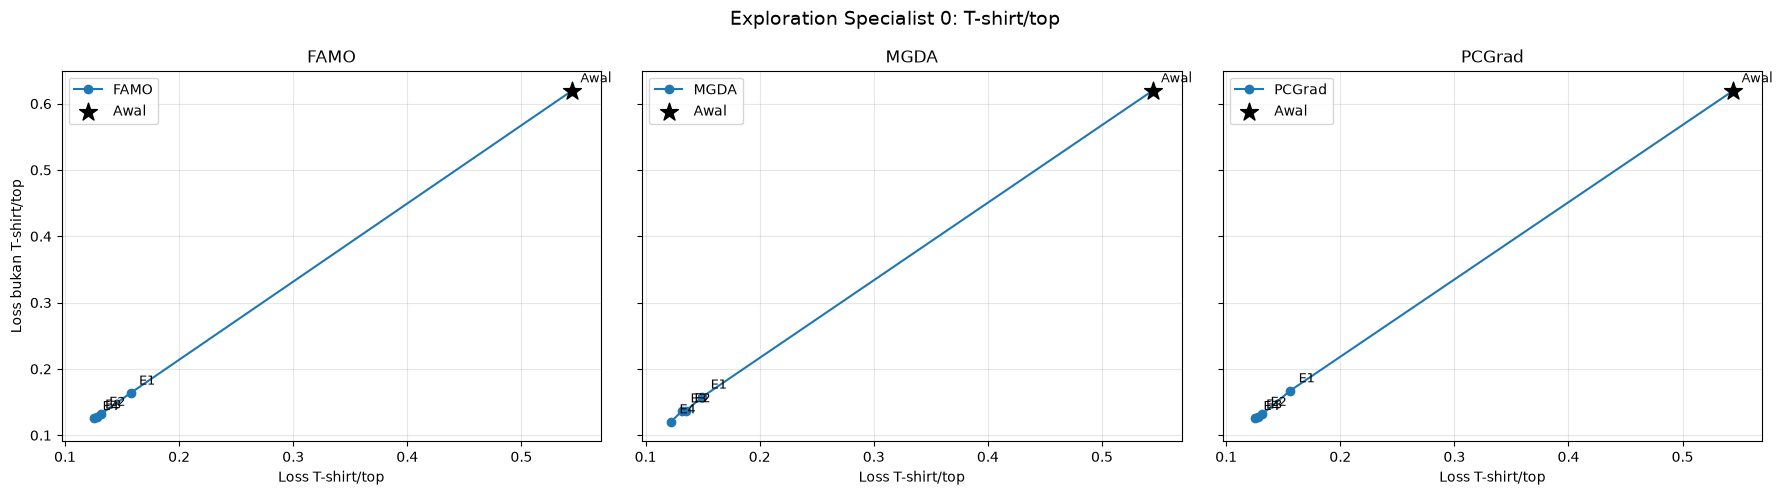

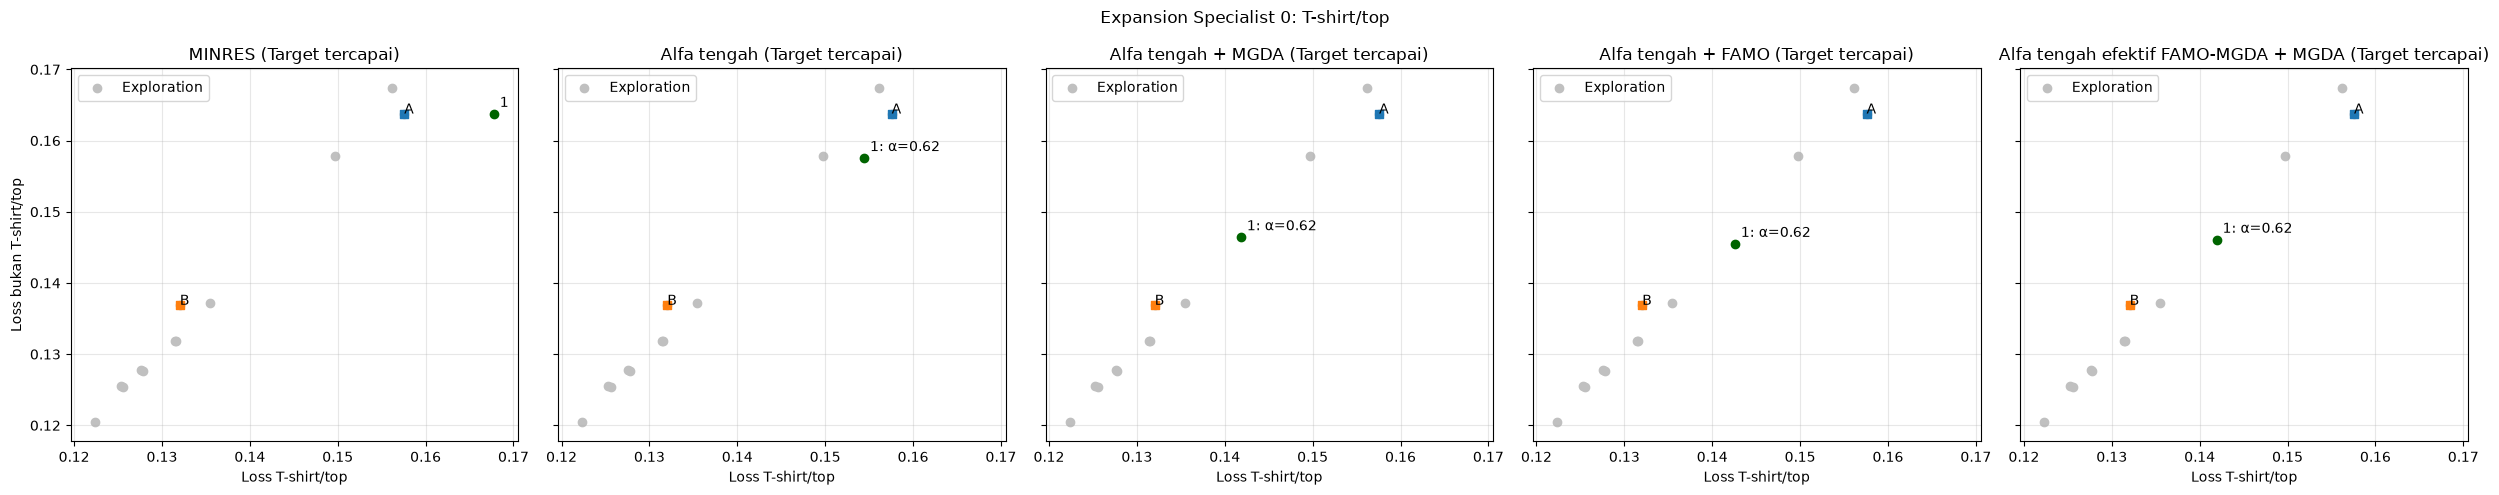

Kandidat nondominated terhadap pool validasi:
  MINRES: 0/1 di front
  Alfa tengah: 0/1 di front
  Alfa tengah + MGDA: 0/1 di front
  Alfa tengah + FAMO: 0/1 di front
  Alfa tengah efektif FAMO-MGDA + MGDA: 0/1 di front

SPECIALIST 0: T-shirt/top
Metode                                                Status            Acc test      Prec    Recall        F1       AUC
Tanpa exploration/expansion                           ok                  0.9525    0.8378    0.6510    0.7327    0.9727
Exploration terbaik                                   ok                  0.9539    0.7822    0.7470    0.7642    0.9741
Exploration PCGrad                                    ok                  0.9525    0.8378    0.6510    0.7327    0.9727
Exploration MGDA                                      ok                  0.9539    0.7822    0.7470    0.7642    0.9741
Exploration FAMO                                      ok                  0.9523    0.8374    0.6490    0.7313    0.9726
Expansion MINRES           

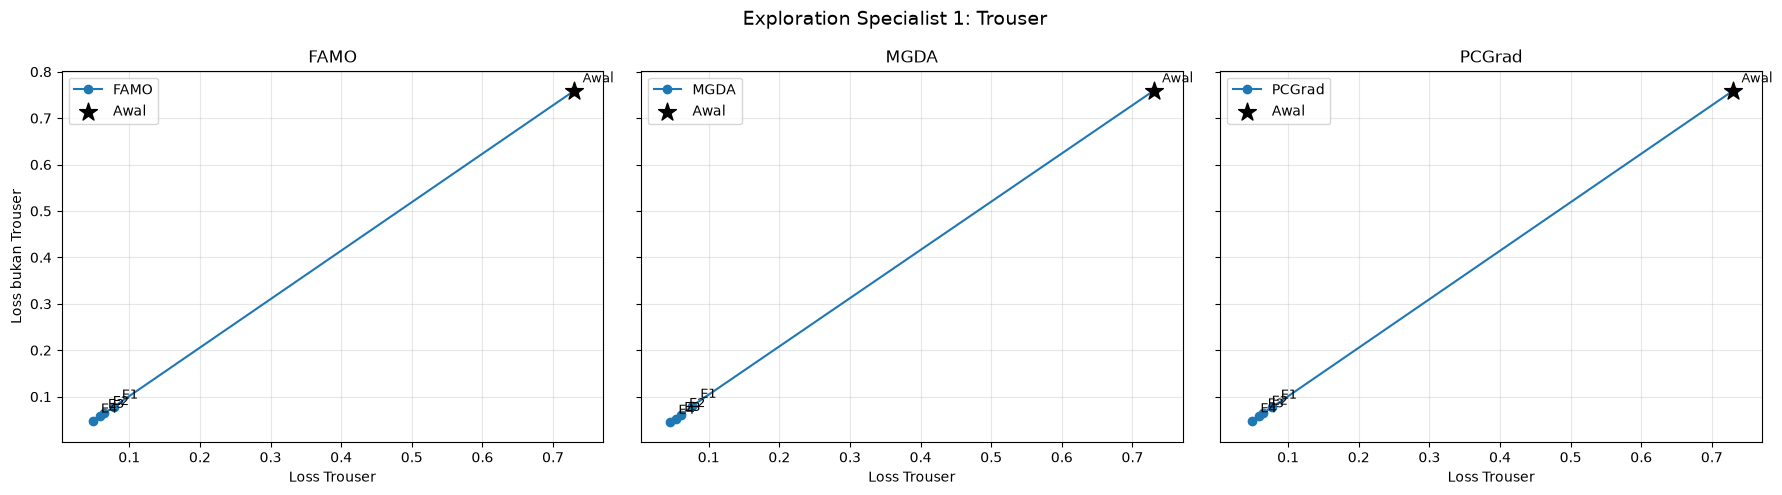

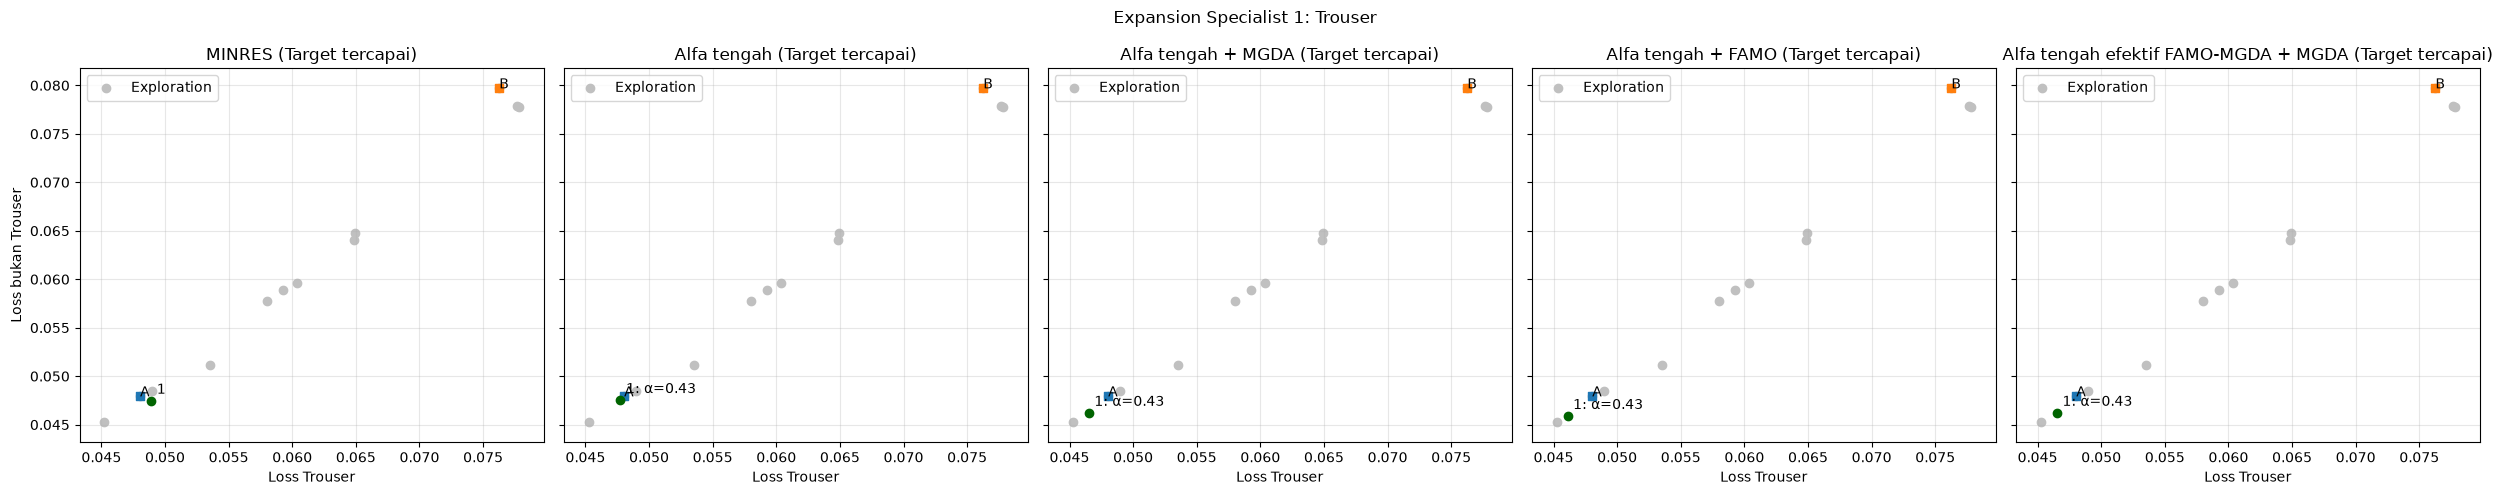

Kandidat nondominated terhadap pool validasi:
  MINRES: 0/1 di front
  Alfa tengah: 0/1 di front
  Alfa tengah + MGDA: 0/1 di front
  Alfa tengah + FAMO: 0/1 di front
  Alfa tengah efektif FAMO-MGDA + MGDA: 0/1 di front

SPECIALIST 1: Trouser
Metode                                                Status            Acc test      Prec    Recall        F1       AUC
Tanpa exploration/expansion                           ok                  0.9845    0.9679    0.8740    0.9185    0.9922
Exploration terbaik                                   ok                  0.9854    0.9514    0.9000    0.9250    0.9928
Exploration PCGrad                                    ok                  0.9845    0.9679    0.8740    0.9185    0.9922
Exploration MGDA                                      ok                  0.9854    0.9514    0.9000    0.9250    0.9928
Exploration FAMO                                      ok                  0.9849    0.9660    0.8800    0.9210    0.9926
Expansion MINRES               

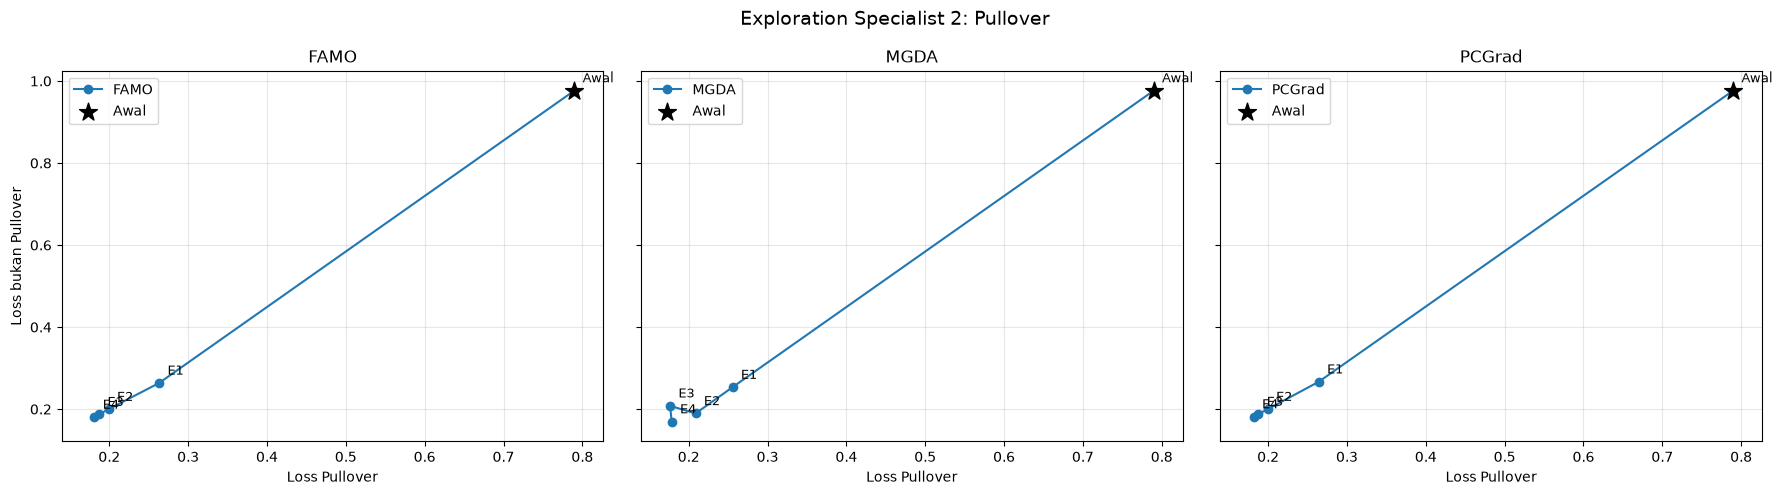

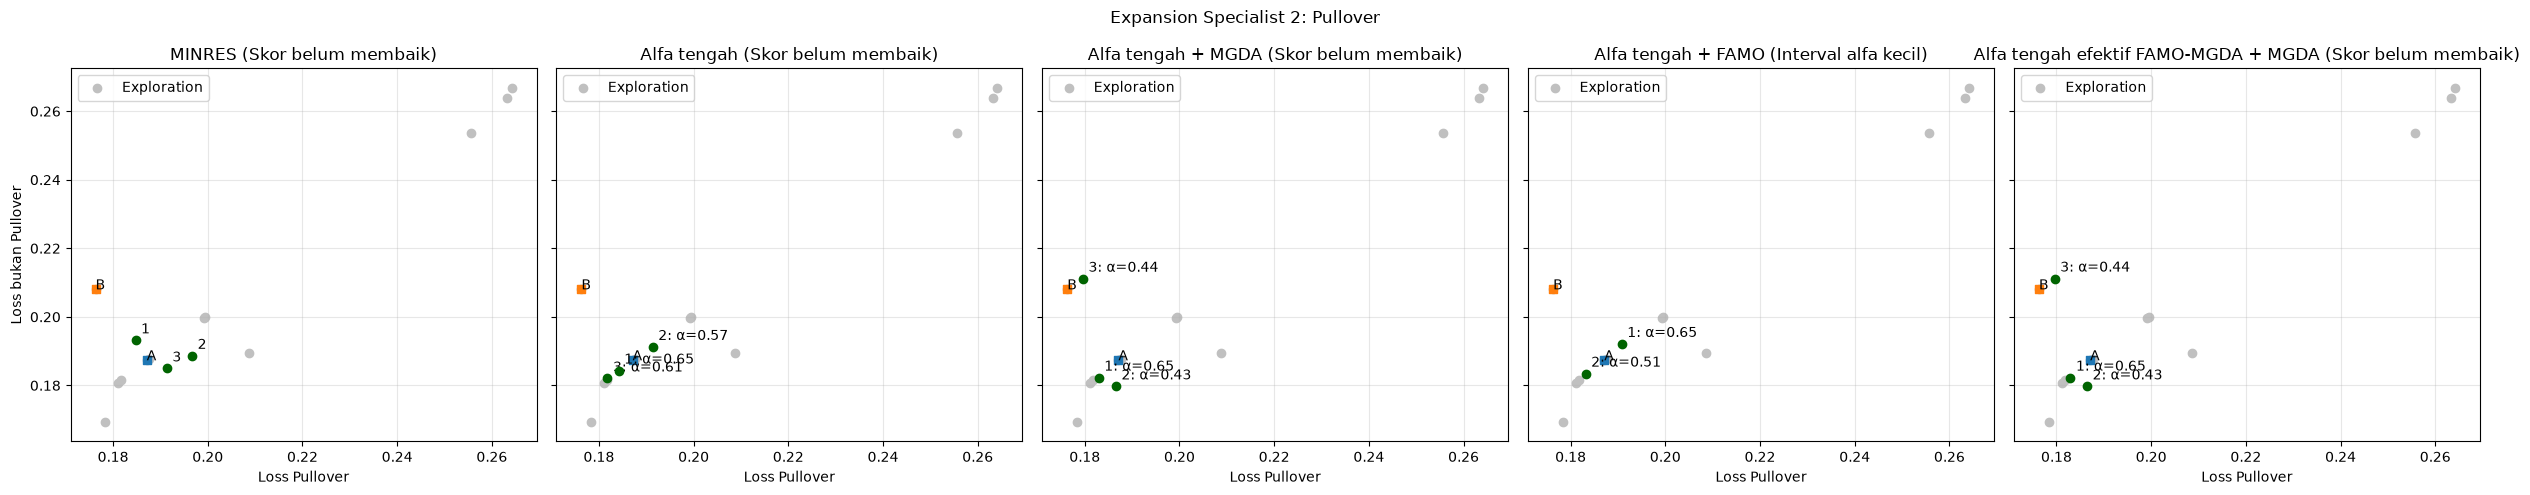

Kandidat nondominated terhadap pool validasi:
  MINRES: 0/3 di front
  Alfa tengah: 0/3 di front
  Alfa tengah + MGDA: 0/3 di front
  Alfa tengah + FAMO: 0/2 di front
  Alfa tengah efektif FAMO-MGDA + MGDA: 0/3 di front

SPECIALIST 2: Pullover
Metode                                                Status            Acc test      Prec    Recall        F1       AUC
Tanpa exploration/expansion                           ok                  0.9180    0.7296    0.2860    0.4109    0.9402
Exploration terbaik                                   ok                  0.9236    0.8278    0.2980    0.4382    0.9465
Exploration PCGrad                                    ok                  0.9177    0.7275    0.2830    0.4075    0.9401
Exploration MGDA                                      ok                  0.9236    0.8278    0.2980    0.4382    0.9465
Exploration FAMO                                      ok                  0.9189    0.7392    0.2920    0.4186    0.9407
Expansion MINRES              

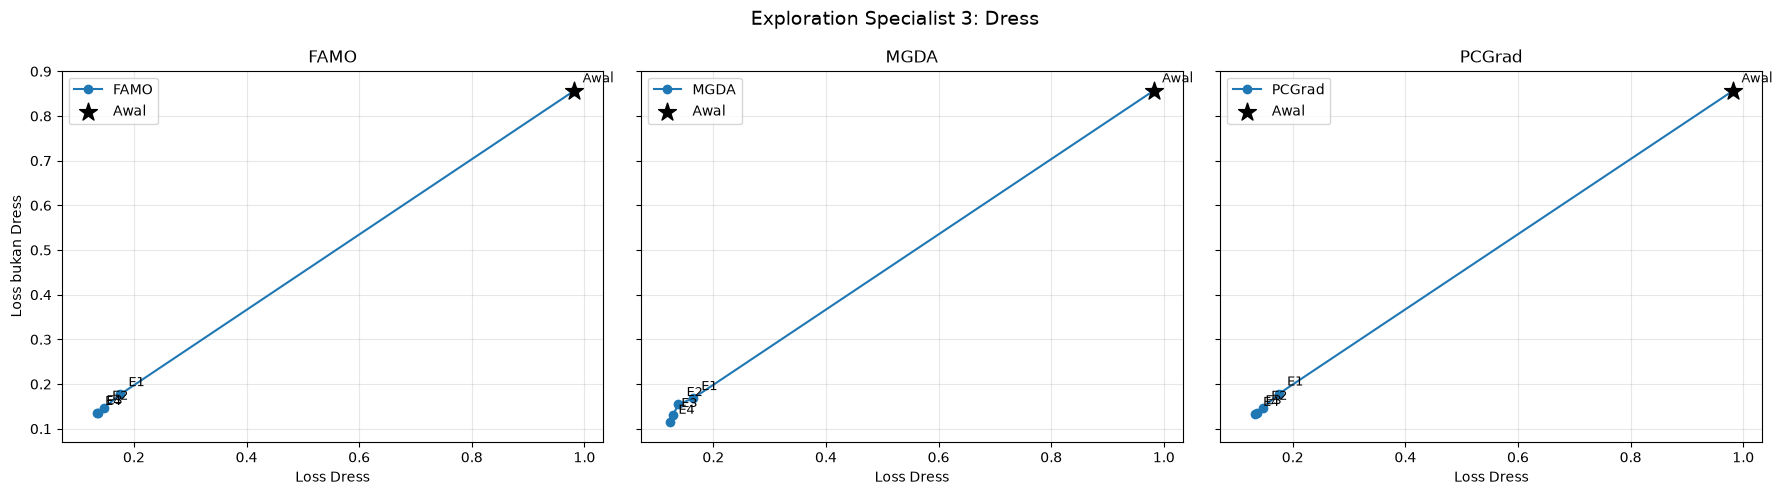

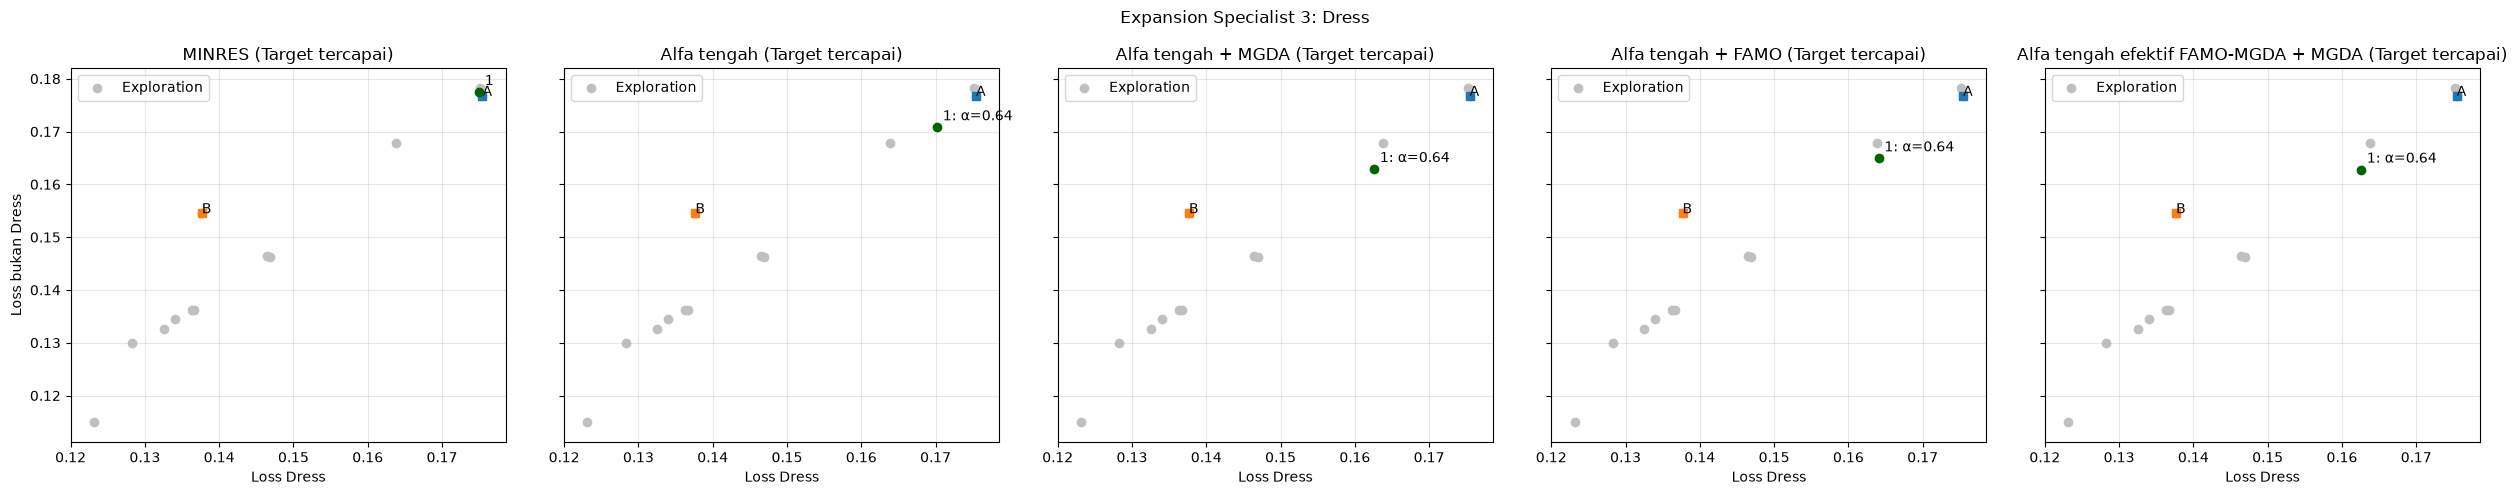

Kandidat nondominated terhadap pool validasi:
  MINRES: 0/1 di front
  Alfa tengah: 0/1 di front
  Alfa tengah + MGDA: 0/1 di front
  Alfa tengah + FAMO: 0/1 di front
  Alfa tengah efektif FAMO-MGDA + MGDA: 0/1 di front

SPECIALIST 3: Dress
Metode                                                Status            Acc test      Prec    Recall        F1       AUC
Tanpa exploration/expansion                           ok                  0.9443    0.8748    0.5170    0.6499    0.9621
Exploration terbaik                                   ok                  0.9500    0.7385    0.7740    0.7559    0.9671
Exploration PCGrad                                    ok                  0.9443    0.8748    0.5170    0.6499    0.9621
Exploration MGDA                                      ok                  0.9500    0.7385    0.7740    0.7559    0.9671
Exploration FAMO                                      ok                  0.9433    0.8765    0.5040    0.6400    0.9619
Expansion MINRES                 

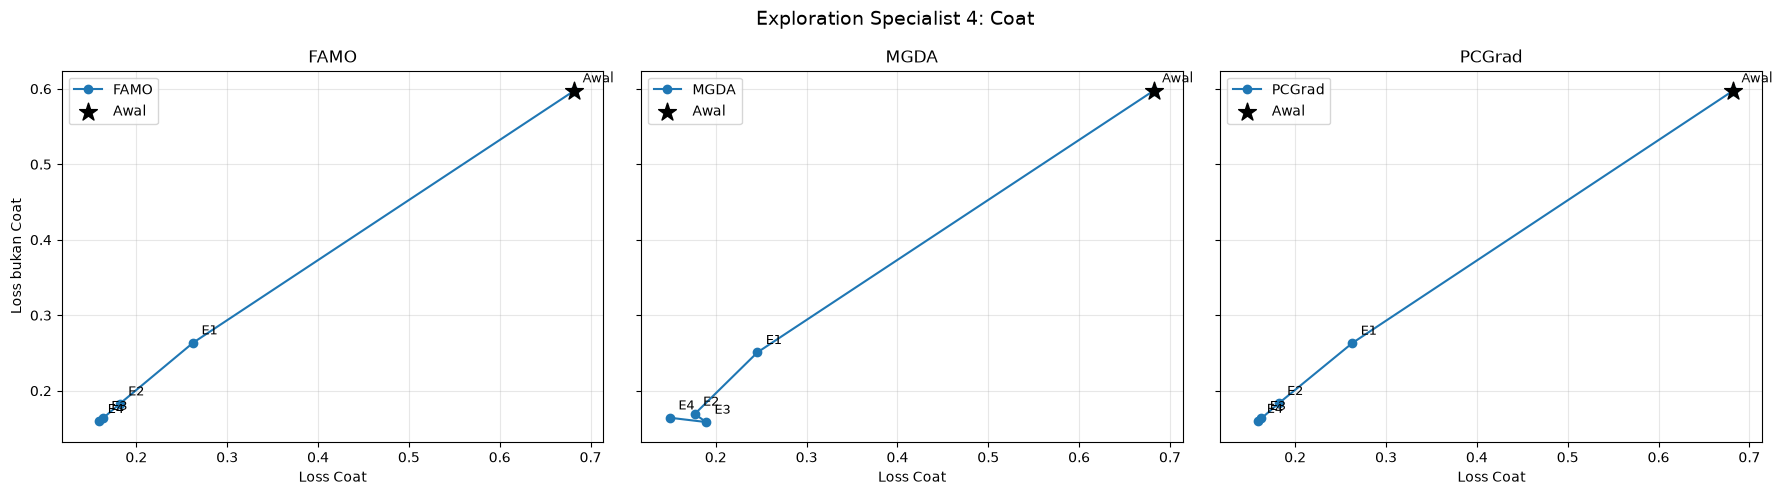

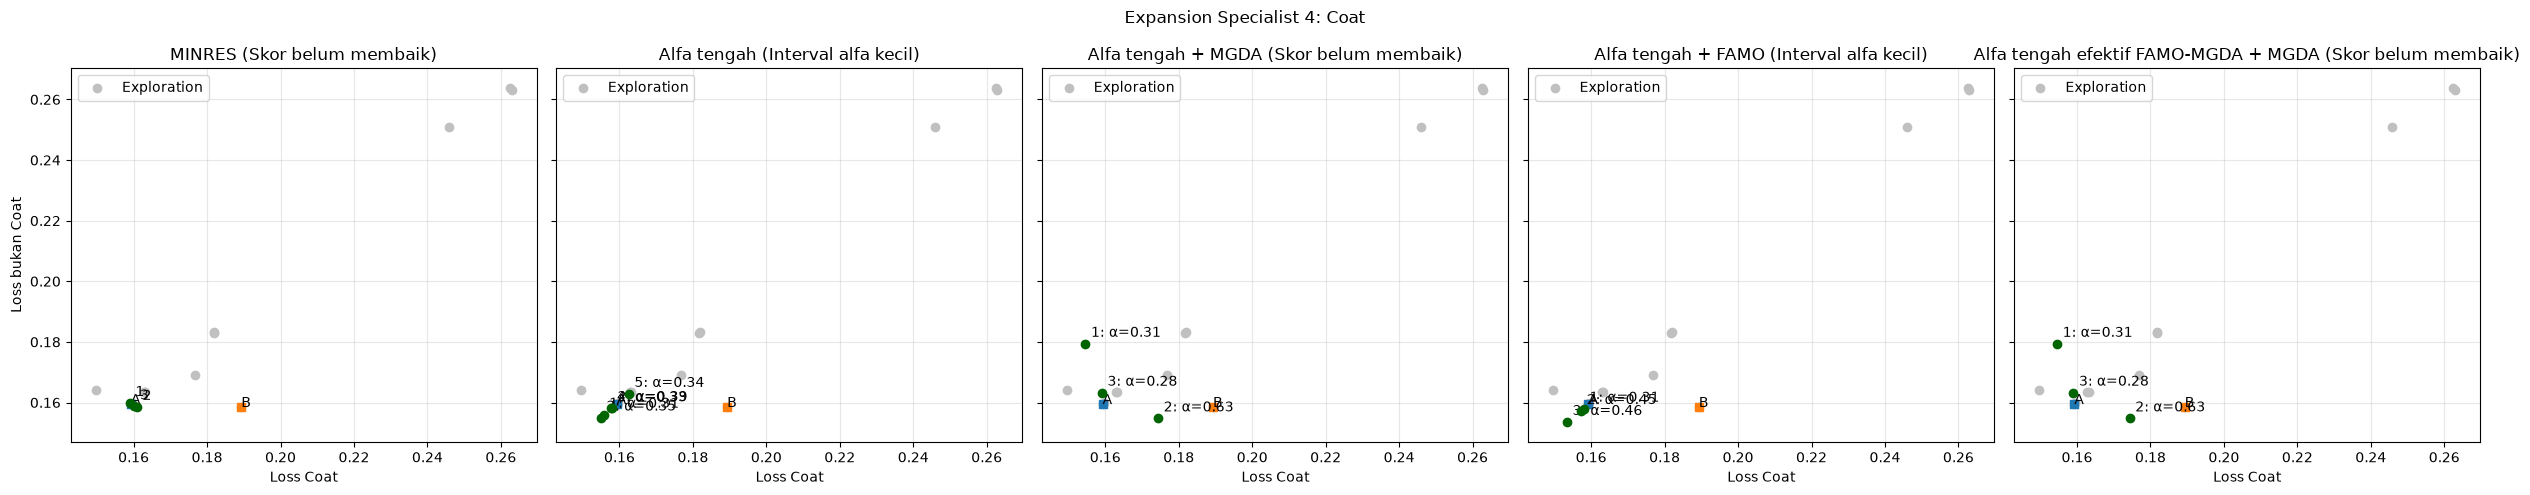

Kandidat nondominated terhadap pool validasi:
  MINRES: 0/3 di front
  Alfa tengah: 0/5 di front
  Alfa tengah + MGDA: 0/3 di front
  Alfa tengah + FAMO: 1/3 di front
  Alfa tengah efektif FAMO-MGDA + MGDA: 0/3 di front

SPECIALIST 4: Coat
Metode                                                Status            Acc test      Prec    Recall        F1       AUC
Tanpa exploration/expansion                           ok                  0.9261    0.7310    0.4130    0.5278    0.9518
Exploration terbaik                                   ok                  0.9268    0.7295    0.4260    0.5379    0.9516
Exploration PCGrad                                    ok                  0.9262    0.7306    0.4150    0.5293    0.9518
Exploration MGDA                                      ok                  0.9326    0.6945    0.5820    0.6333    0.9558
Exploration FAMO                                      ok                  0.9268    0.7295    0.4260    0.5379    0.9516
Expansion MINRES                  

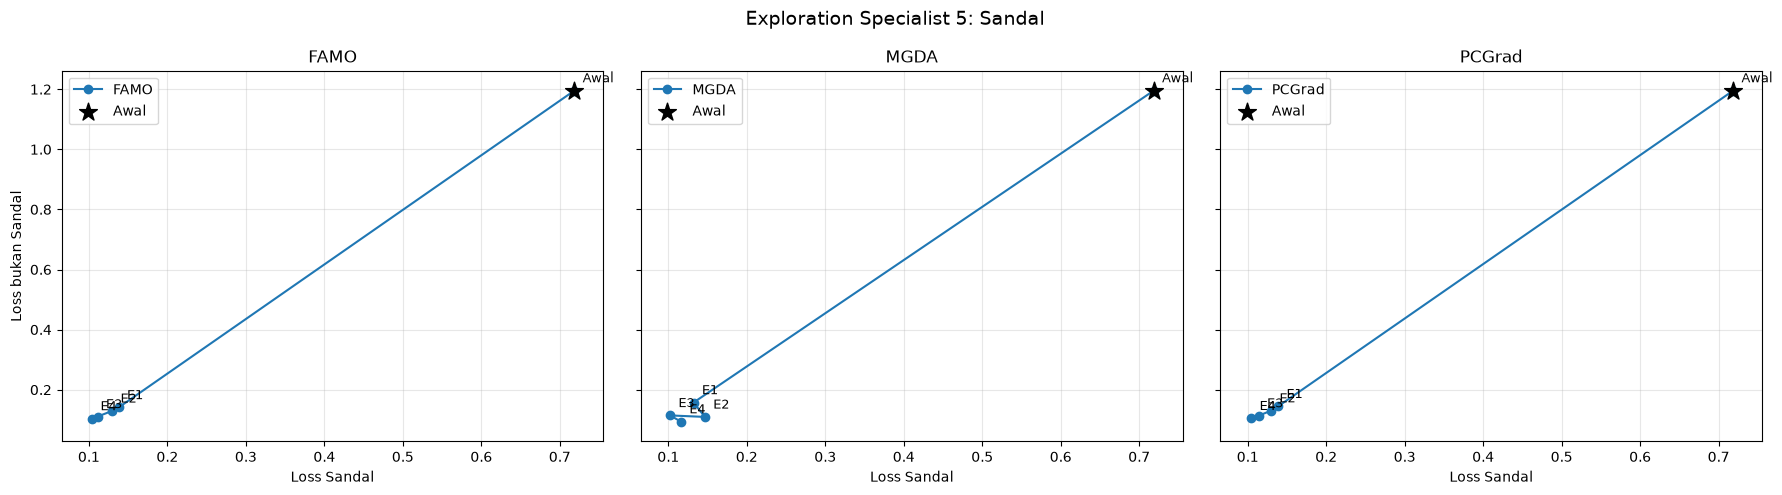

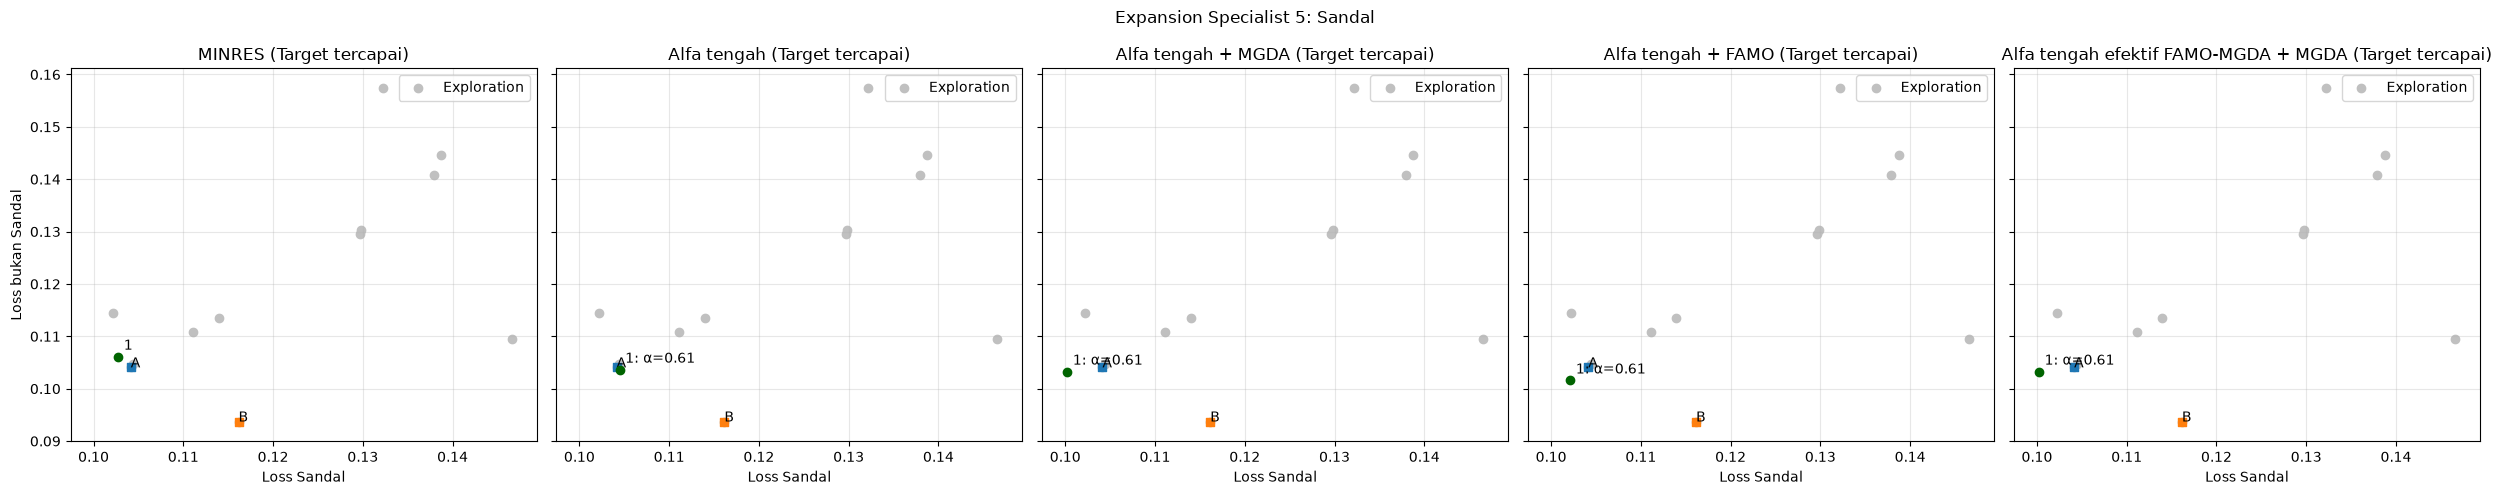

Kandidat nondominated terhadap pool validasi:
  MINRES: 0/1 di front
  Alfa tengah: 0/1 di front
  Alfa tengah + MGDA: 1/1 di front
  Alfa tengah + FAMO: 1/1 di front
  Alfa tengah efektif FAMO-MGDA + MGDA: 0/1 di front

SPECIALIST 5: Sandal
Metode                                                Status            Acc test      Prec    Recall        F1       AUC
Tanpa exploration/expansion                           ok                  0.9615    0.8160    0.7940    0.8049    0.9828
Exploration terbaik                                   ok                  0.9610    0.8119    0.7940    0.8028    0.9823
Exploration PCGrad                                    ok                  0.9611    0.8153    0.7900    0.8024    0.9826
Exploration MGDA                                      ok                  0.9635    0.8508    0.7700    0.8084    0.9830
Exploration FAMO                                      ok                  0.9610    0.8119    0.7940    0.8028    0.9823
Expansion MINRES                

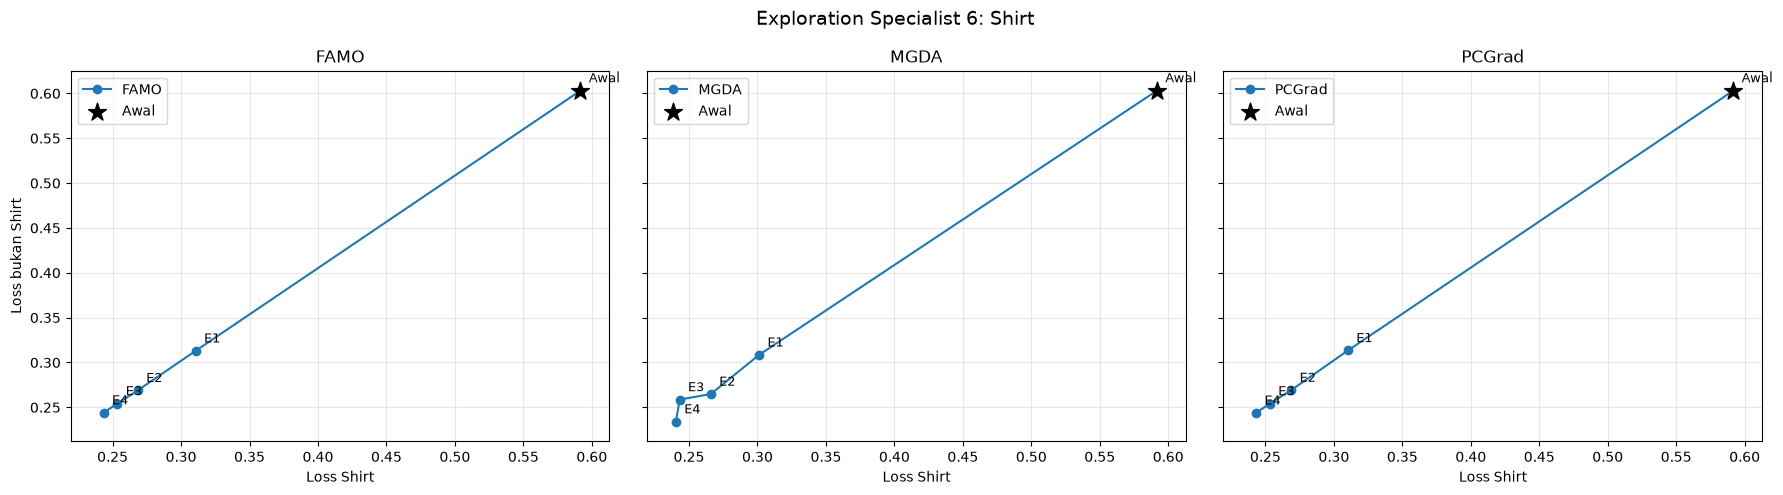

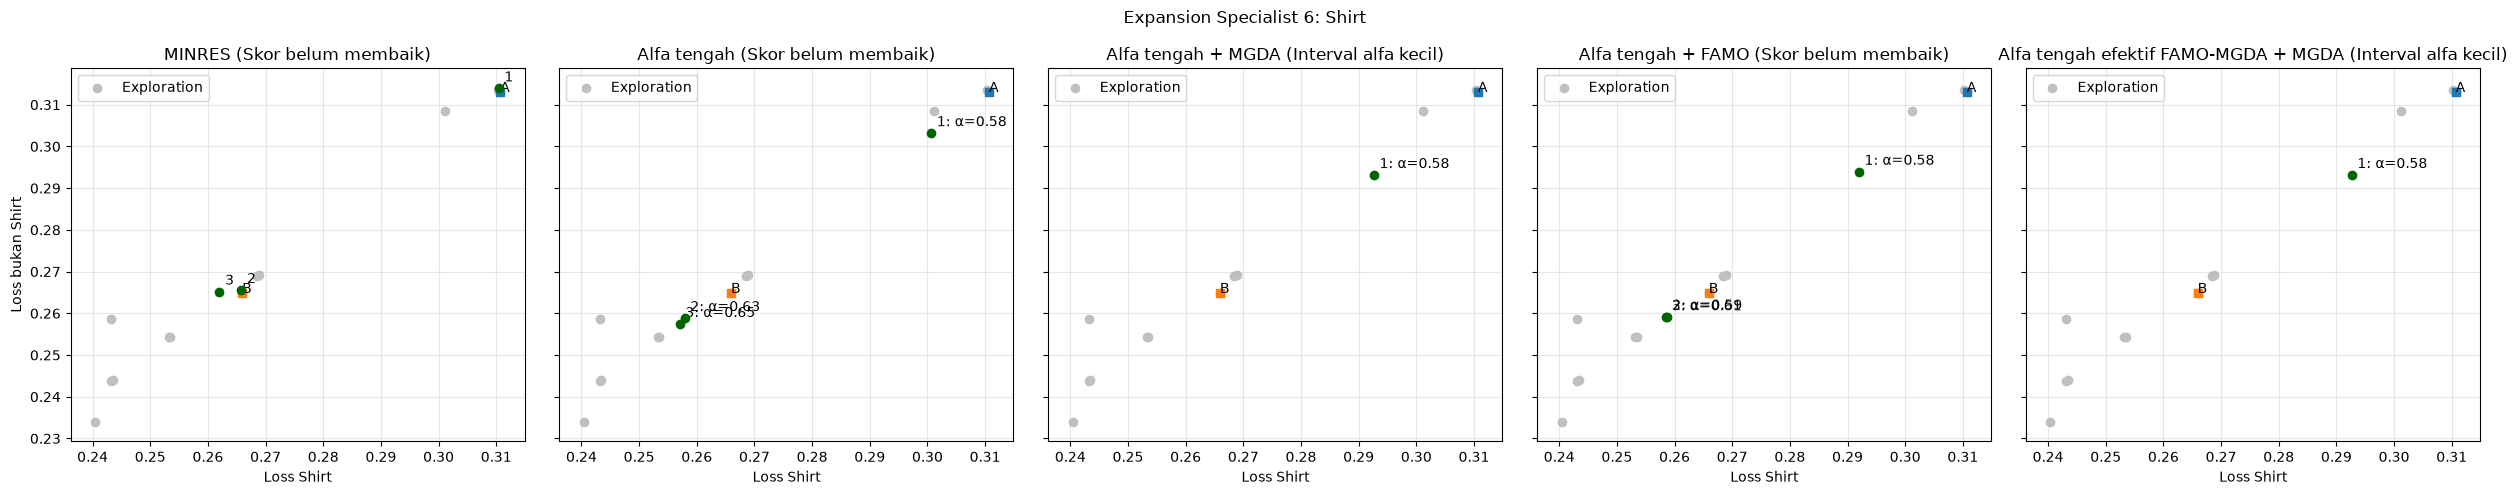

Kandidat nondominated terhadap pool validasi:
  MINRES: 0/3 di front
  Alfa tengah: 0/3 di front
  Alfa tengah + MGDA: 0/1 di front
  Alfa tengah + FAMO: 0/3 di front
  Alfa tengah efektif FAMO-MGDA + MGDA: 0/1 di front

SPECIALIST 6: Shirt
Metode                                                Status            Acc test      Prec    Recall        F1       AUC
Tanpa exploration/expansion                           ok                  0.8991    0.2857    0.0060    0.0118    0.8616
Exploration terbaik                                   ok                  0.8997    0.4981    0.3890    0.4368    0.8774
Exploration PCGrad                                    ok                  0.8991    0.2857    0.0060    0.0118    0.8615
Exploration MGDA                                      ok                  0.8997    0.4981    0.3890    0.4368    0.8774
Exploration FAMO                                      ok                  0.8993    0.3158    0.0060    0.0118    0.8611
Expansion MINRES                 

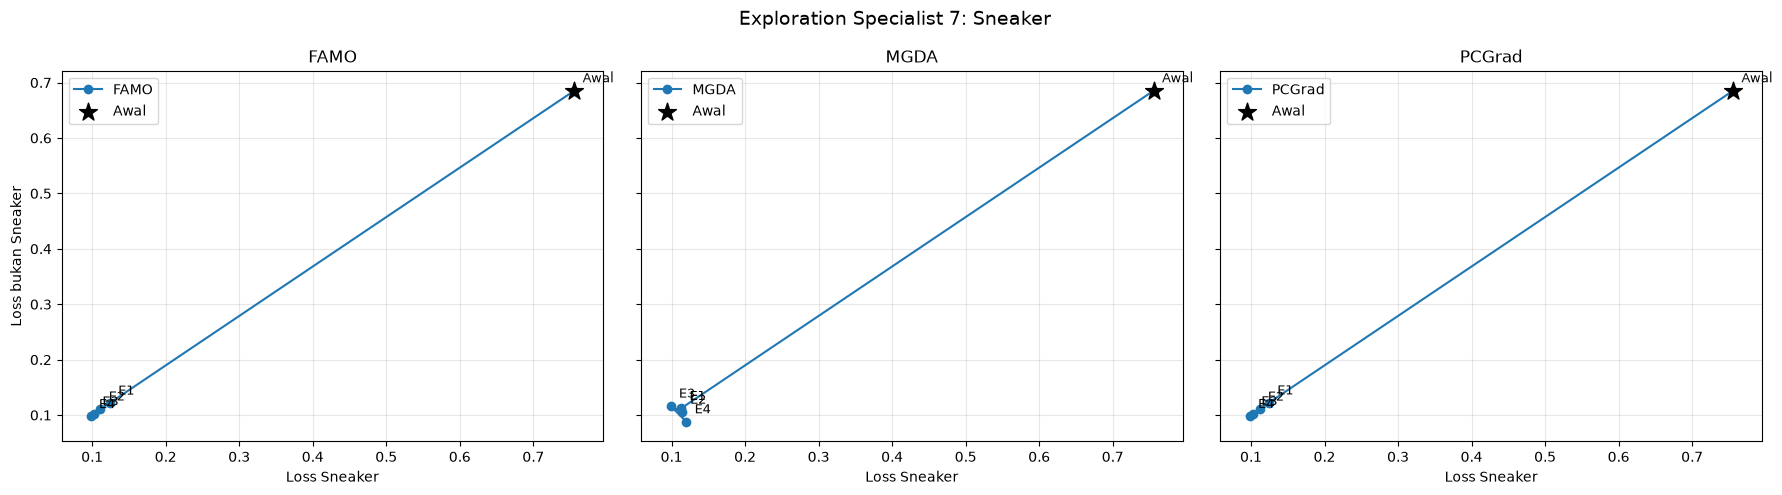

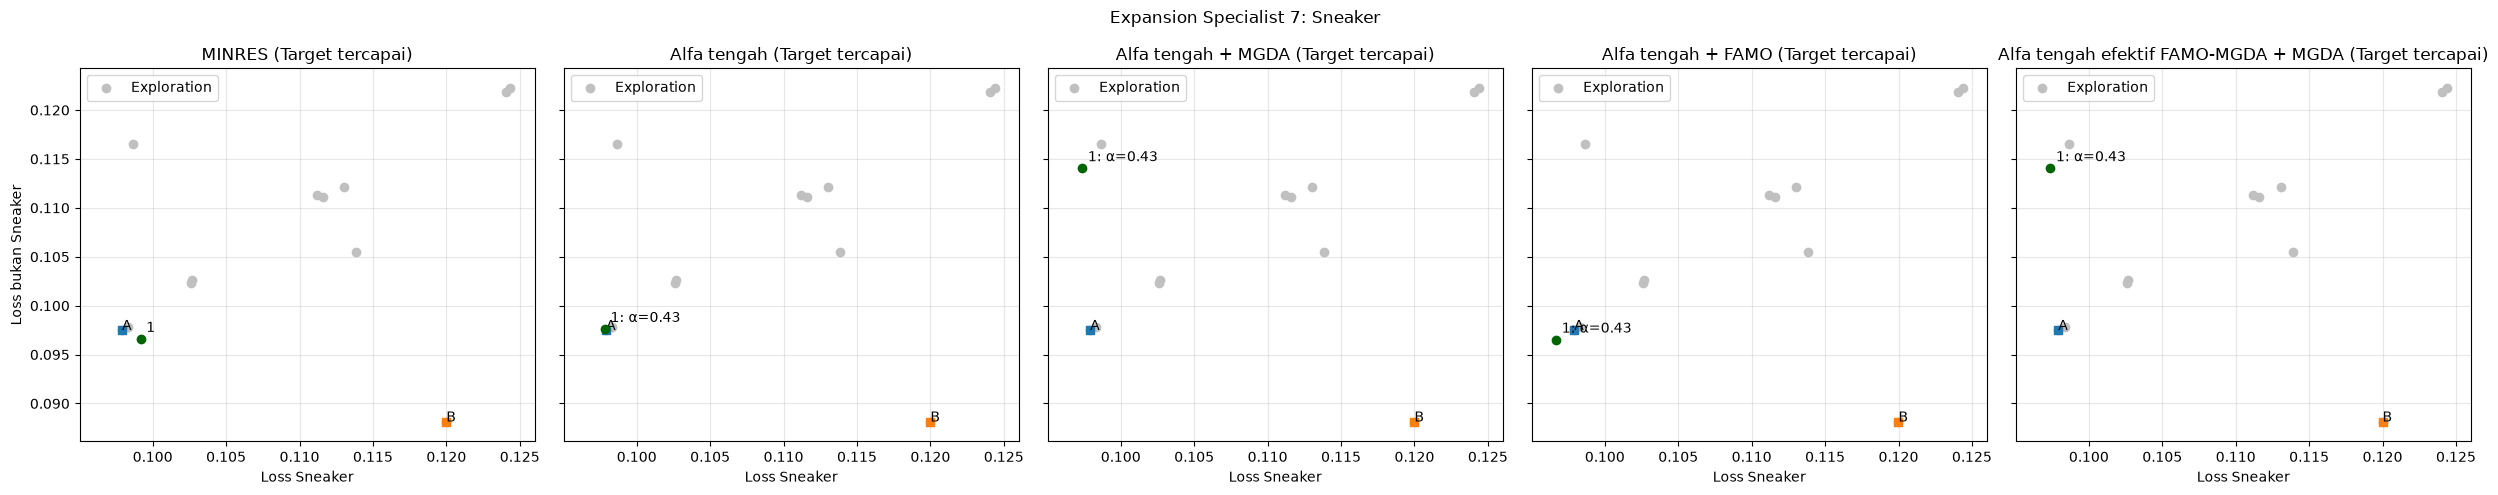

Kandidat nondominated terhadap pool validasi:
  MINRES: 0/1 di front
  Alfa tengah: 0/1 di front
  Alfa tengah + MGDA: 0/1 di front
  Alfa tengah + FAMO: 1/1 di front
  Alfa tengah efektif FAMO-MGDA + MGDA: 0/1 di front

SPECIALIST 7: Sneaker
Metode                                                Status            Acc test      Prec    Recall        F1       AUC
Tanpa exploration/expansion                           ok                  0.9644    0.8114    0.8390    0.8250    0.9881
Exploration terbaik                                   ok                  0.9647    0.8138    0.8390    0.8262    0.9882
Exploration PCGrad                                    ok                  0.9644    0.8114    0.8390    0.8250    0.9881
Exploration MGDA                                      ok                  0.9581    0.7759    0.8170    0.7959    0.9831
Exploration FAMO                                      ok                  0.9647    0.8138    0.8390    0.8262    0.9882
Expansion MINRES               

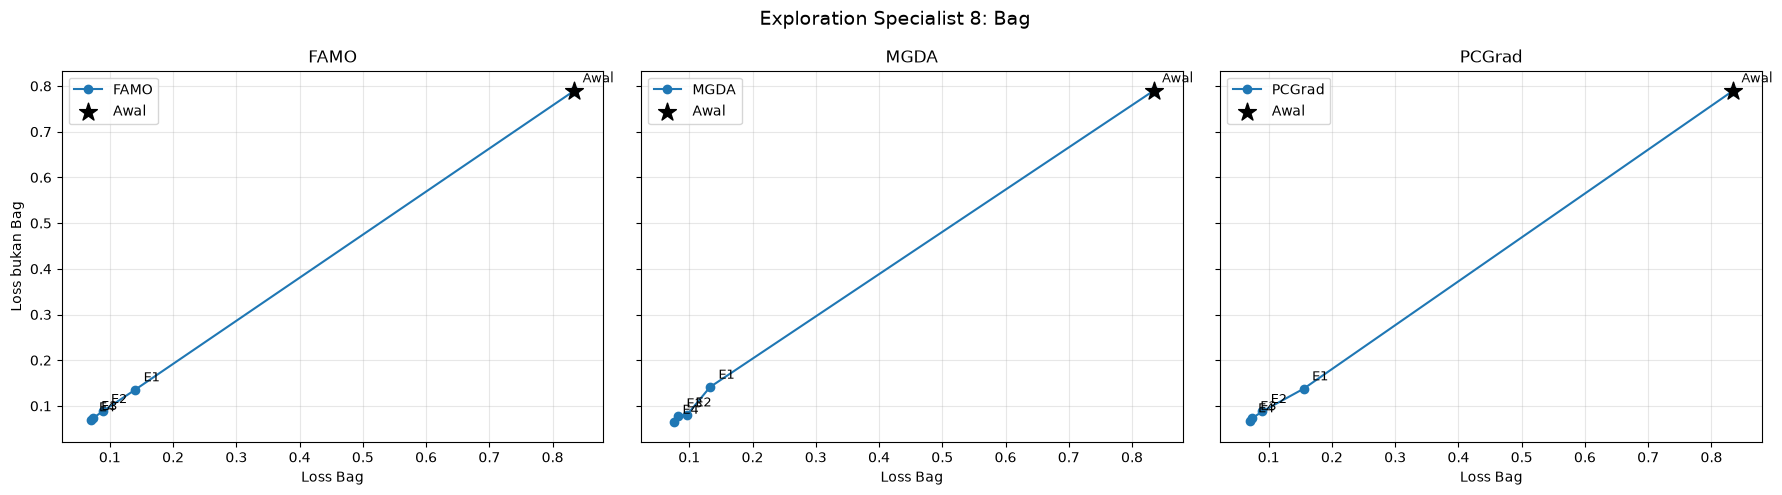

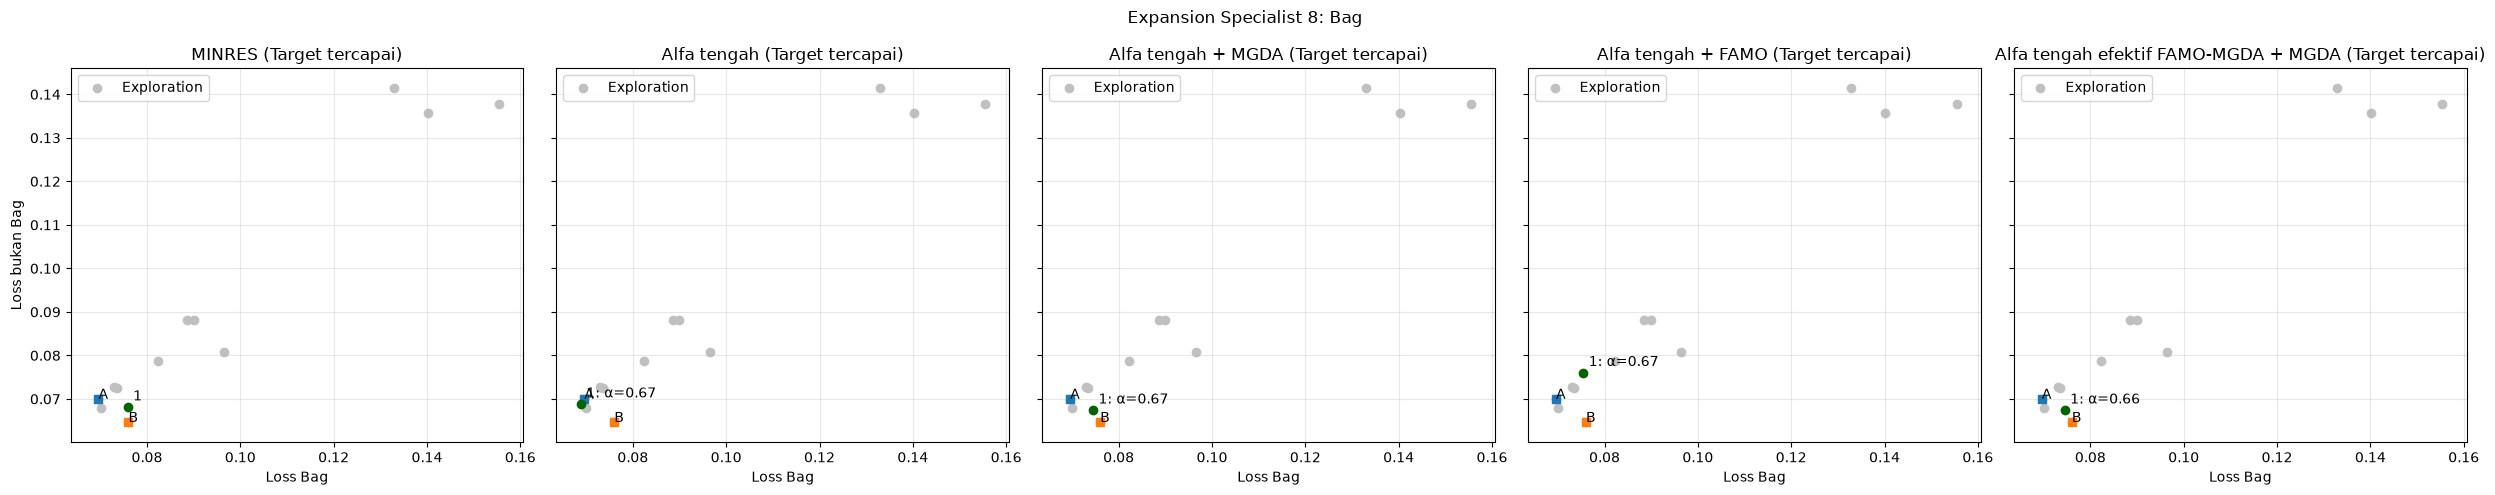

Kandidat nondominated terhadap pool validasi:
  MINRES: 0/1 di front
  Alfa tengah: 1/1 di front
  Alfa tengah + MGDA: 0/1 di front
  Alfa tengah + FAMO: 0/1 di front
  Alfa tengah efektif FAMO-MGDA + MGDA: 1/1 di front

SPECIALIST 8: Bag
Metode                                                Status            Acc test      Prec    Recall        F1       AUC
Tanpa exploration/expansion                           ok                  0.9803    0.9350    0.8630    0.8976    0.9871
Exploration terbaik                                   ok                  0.9804    0.9341    0.8650    0.8982    0.9869
Exploration PCGrad                                    ok                  0.9803    0.9331    0.8650    0.8978    0.9868
Exploration MGDA                                      ok                  0.9788    0.9477    0.8340    0.8872    0.9875
Exploration FAMO                                      ok                  0.9804    0.9341    0.8650    0.8982    0.9869
Expansion MINRES                   

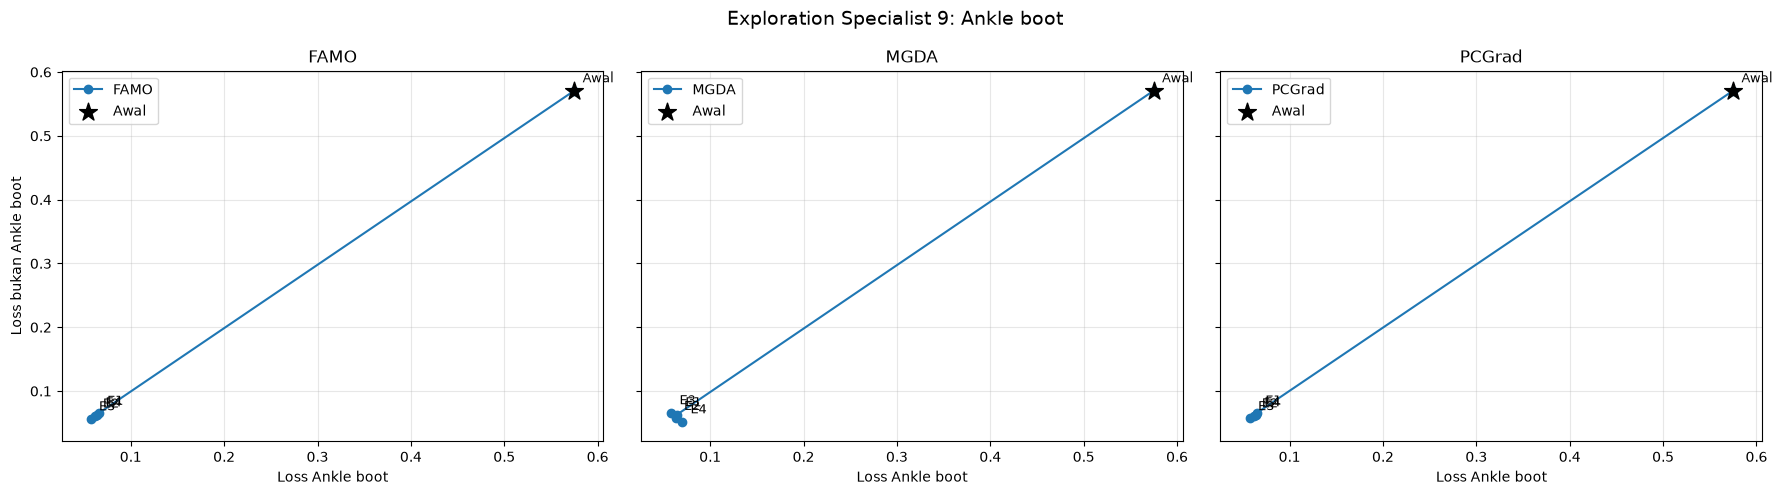

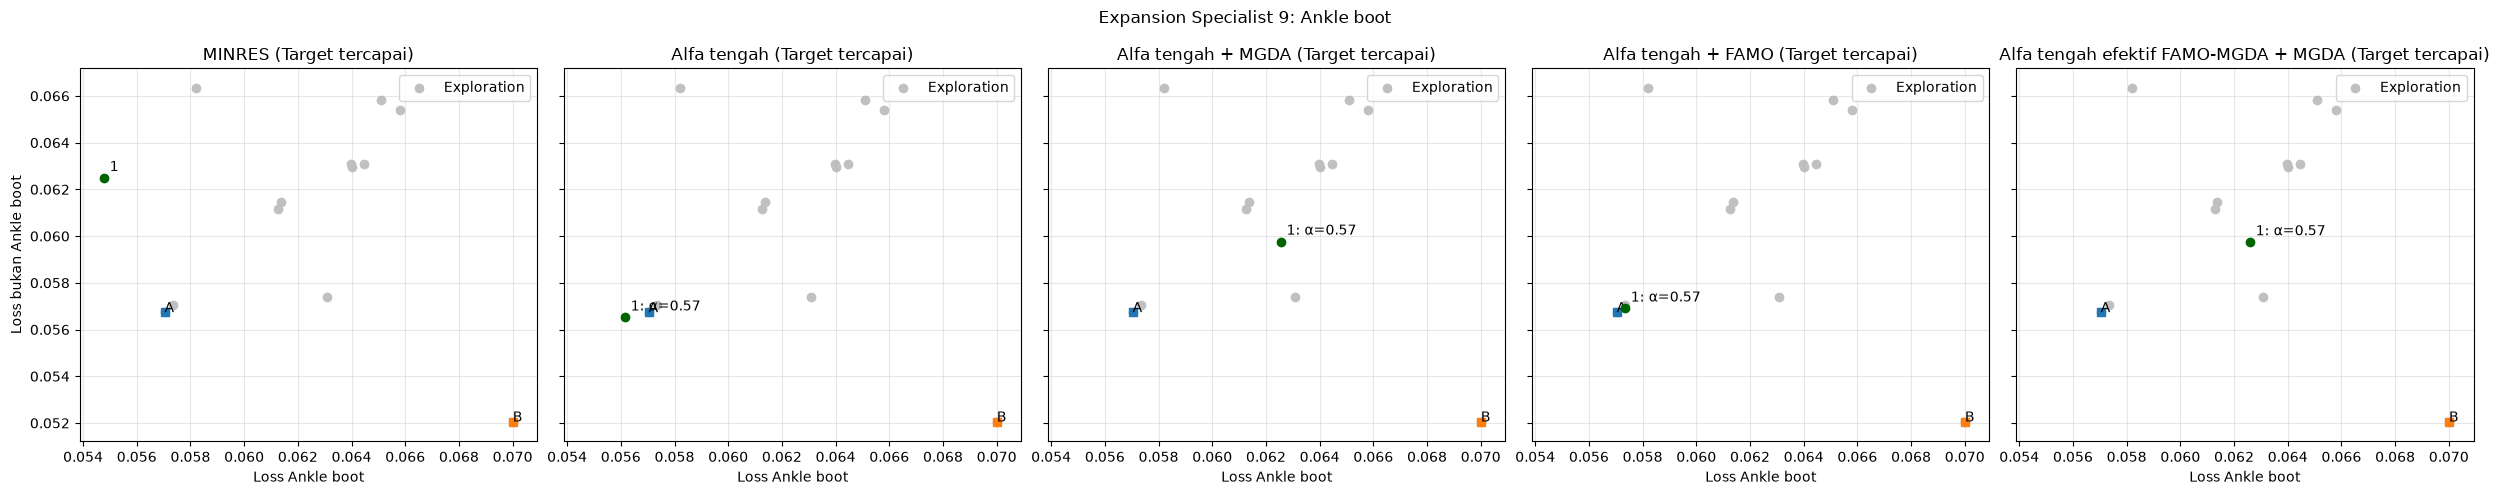

Kandidat nondominated terhadap pool validasi:
  MINRES: 1/1 di front
  Alfa tengah: 1/1 di front
  Alfa tengah + MGDA: 0/1 di front
  Alfa tengah + FAMO: 0/1 di front
  Alfa tengah efektif FAMO-MGDA + MGDA: 0/1 di front

SPECIALIST 9: Ankle boot
Metode                                                Status            Acc test      Prec    Recall        F1       AUC
Tanpa exploration/expansion                           ok                  0.9726    0.8218    0.9270    0.8712    0.9942
Exploration terbaik                                   ok                  0.9727    0.8225    0.9270    0.8717    0.9942
Exploration PCGrad                                    ok                  0.9726    0.8218    0.9270    0.8712    0.9942
Exploration MGDA                                      ok                  0.9737    0.9192    0.8080    0.8600    0.9941
Exploration FAMO                                      ok                  0.9727    0.8225    0.9270    0.8717    0.9942
Expansion MINRES            

In [ ]:
# Sel training yang panjang: 10 kelas × 3 metode exploration × 5 metode expansion, serta baseline dan evaluasi.
teachers = []
specialist_summaries = []
for class_id in range(len(CLASS_NAMES)):
    print(f"\n===== {class_id}/9: {CLASS_NAMES[class_id]} =====")
    teacher, summary = run_specialist_class(class_id)
    teachers.append(teacher)
    specialist_summaries.append(summary)
    print('TERPILIH:', summary['selected_method'],
          '| valid:', np.round(summary['selected_valid'], 4),
          '| test:', np.round(summary['selected_test'], 4))

assert len(teachers) == len(CLASS_NAMES)
print('Selesai: seluruh 10 teacher dibuat dari hasil Pareto Exploration/Expansion.')


In [ ]:
# Ringkasan semua metode termasuk midpoint yang di-refine.
print('Kelas | Teacher terpilih | valid minimax | metode expansion: jumlah ronde / front')
for s in specialist_summaries:
    counts = s['pareto_front_counts']
    desc = ' | '.join(
        f"{name}: {info['rounds']}/{counts.get(name, 0)}"
        for name, info in s['expansion'].items() if name != 'Tanpa expand'
    )
    print(f"{s['class_name']:12} | {s['selected_method']:20} | "
          f"{s['selected_score']:.4f} | {desc}")


# Simpan metrik semua specialist: satu baris per kelas × metode, plus detail JSON.
specialist_rows = [row for s in specialist_summaries for row in s['metrics_comparison']]
save_metrics_reports('specialists', specialist_rows)
print('\nRata-rata F1 TEST per metode (hanya kelas yang memiliki kandidat):')
for method in dict.fromkeys(row['method'] for row in specialist_rows):
    f1_values = [row['test_f1'] for row in specialist_rows
                 if row['method'] == method and row['status'] == 'ok']
    print(f'  {method:49} {np.mean(f1_values):.4f} ({len(f1_values)}/10 kelas)'
          if f1_values else f'  {method:49} tidak ada kandidat')


Kelas | Teacher terpilih | valid minimax | metode expansion: jumlah ronde / front
T-shirt/top  | MGDA                 | 0.1223 | MINRES: 1/0 | Alfa tengah: 1/0 | Alfa tengah + MGDA: 1/0 | Alfa tengah + FAMO: 1/0 | Alfa tengah efektif FAMO-MGDA + MGDA: 1/0
Trouser      | MGDA                 | 0.0453 | MINRES: 1/0 | Alfa tengah: 1/0 | Alfa tengah + MGDA: 1/0 | Alfa tengah + FAMO: 1/0 | Alfa tengah efektif FAMO-MGDA + MGDA: 1/0
Pullover     | MGDA                 | 0.1784 | MINRES: 3/0 | Alfa tengah: 3/0 | Alfa tengah + MGDA: 3/0 | Alfa tengah + FAMO: 2/0 | Alfa tengah efektif FAMO-MGDA + MGDA: 3/0
Dress        | MGDA                 | 0.1231 | MINRES: 1/0 | Alfa tengah: 1/0 | Alfa tengah + MGDA: 1/0 | Alfa tengah + FAMO: 1/0 | Alfa tengah efektif FAMO-MGDA + MGDA: 1/0
Coat         | Alfa tengah + FAMO   | 0.1536 | MINRES: 3/0 | Alfa tengah: 5/0 | Alfa tengah + MGDA: 3/0 | Alfa tengah + FAMO: 3/1 | Alfa tengah efektif FAMO-MGDA + MGDA: 3/0
Sandal       | Alfa tengah + FAMO   | 0.1021 | M

## Generalist CNN: 10 head × 2 logit, **10 objective Pareto**

Generalist melihat **kanvas gabungan penuh**, menggunakan target lunak dari kesepuluh teacher saat training dan label asli saat evaluasi. Setiap kelas memiliki 1 head dengan 2 output (hadir dan tidak hadir), sehingga forward mengembalikan `(B, 10, 2)`.

**Optimasi 10 tugas:** loss tugas kelas *c* = rata-rata BCE *hadir* dan *tidak hadir* untuk kelas *c*. Berbeda dari notebook sebelumnya yang hanya memakai 2 loss agregat semua kelas, kini PCGrad, MGDA, FAMO, MINRES, dan Alfa tengah menggunakan **10 loss terpisah**. `score = max(10 loss validasi)` dan bobot alpha memiliki 10 komponen.

Grafik 2D masih menggunakan **rata-rata loss hadir (X)** dan **rata-rata loss tidak hadir (Y)** hanya untuk visualisasi. Pareto/dominasi serta pemilihan kandidat memakai vektor 10 tujuan, bukan kedua koordinat pada grafik.


Untuk Generalist, **accuracy biasa** berarti *Hamming/label accuracy*, sedangkan **exact-match accuracy** mengharuskan seluruh 10 kelas benar pada satu gambar. Precision/recall/F1 dilaporkan sebagai micro, macro, weighted, dan per kelas. Tidak menggunakan `argmax` karena sebuah kanvas dapat memiliki lebih dari satu kelas sekaligus.


In [ ]:
class Generalist(Specialist):
    def __init__(self):
        super().__init__()
        # Satu backbone bersama; tiap lapisan menghasilkan dua skor untuk satu kelas.
        self.heads = nn.ModuleList(nn.Linear(32, 2) for _ in CLASS_NAMES)

    def forward(self, x):
        features = self.backbone(x)
        return torch.stack([head(features) for head in self.heads], dim=1)

In [ ]:
@torch.no_grad()
def teacher_targets(images, positions, teachers):
    # Satu guru menilai setiap crop yang terisi. Ambil peluang tertinggi antar-crop.
    target = torch.zeros(len(images), len(teachers))
    for slot in range(positions.shape[1]):
        rows = np.flatnonzero(positions[:, slot, 0] >= 0)
        crops = crop_pad(images, positions, slot)
        for start_row in range(0, len(rows), CFG['BS']):
            ids = rows[start_row:start_row + CFG['BS']]
            x = prep(torch.from_numpy(crops[ids]).to(dev))
            prob = torch.stack([t(x)[:, 0].sigmoid() for t in teachers], dim=1).cpu()
            target[ids] = torch.maximum(target[ids], prob)
    return target

In [ ]:
def generalist_data(images, labels, size, seed, teachers=None):
    # ID kelas tiap slot menjadi label hadir/tidak untuk evaluasi. Guru memberikan target latih.
    canvas, slots, positions = make_multi_flexible(images, labels, size, seed=seed)
    if teachers is None:
        target = torch.stack([torch.from_numpy((slots == c).any(axis=1))
                              for c in range(len(CLASS_NAMES))], dim=1).float()
    else:
        target = teacher_targets(canvas, positions, teachers)
    return torch.from_numpy(canvas), target

In [ ]:
gen_train = generalist_data(fa_tr_x, fa_tr_y, 20000, 1, teachers)
gen_valid = generalist_data(fa_val_x, fa_val_y, 2000, 2)
gen_test = generalist_data(fa_te_x, fa_te_y, 5000, 3)

In [ ]:
# Exploration Generalist: setiap metode dari bobot CNN yang sama, 10 objective per kelas.
set_seed(CFG['SEED'])
gen_initial = Generalist().to(dev)
gen_start = checkpoint(gen_initial, 'Awal', valid=gen_valid)
assert gen_start['objectives'].shape == (len(CLASS_NAMES),)
assert gen_initial(prep(gen_train[0][:2].to(dev))).shape == (2, len(CLASS_NAMES), 2)
gen_baseline_paths = train_standard_baseline(
    gen_initial, train=gen_train, valid=gen_valid, class_id=None
)
gen_paths = {
    m: explore(gen_initial, m, gen_train, gen_valid)
    for m in ('PCGrad', 'MGDA', 'FAMO')
}


    [Baseline] epoch 1/4 batch 100/157
    [Baseline] epoch 1/4 batch 157/157
    [Baseline] epoch 2/4 batch 100/157
    [Baseline] epoch 2/4 batch 157/157
    [Baseline] epoch 3/4 batch 100/157
    [Baseline] epoch 3/4 batch 157/157
    [Baseline] epoch 4/4 batch 100/157
    [Baseline] epoch 4/4 batch 157/157
[Generalis] PCGrad epoch 1/4 (157 batch)
    batch 100/157 | 2.8s
    batch 157/157 | 4.4s
    selesai epoch 1: minimax valid=0.65237
[Generalis] PCGrad epoch 2/4 (157 batch)
    batch 100/157 | 2.7s
    batch 157/157 | 4.3s
    selesai epoch 2: minimax valid=0.65009
[Generalis] PCGrad epoch 3/4 (157 batch)
    batch 100/157 | 2.7s
    batch 157/157 | 4.2s
    selesai epoch 3: minimax valid=0.65561
[Generalis] PCGrad epoch 4/4 (157 batch)
    batch 100/157 | 2.8s
    batch 157/157 | 4.5s
    selesai epoch 4: minimax valid=0.65951
[Generalis] MGDA epoch 1/4 (157 batch)
    batch 100/157 | 3.0s
    batch 157/157 | 4.8s
    selesai epoch 1: minimax valid=0.65046
[Generalis] MGDA epo

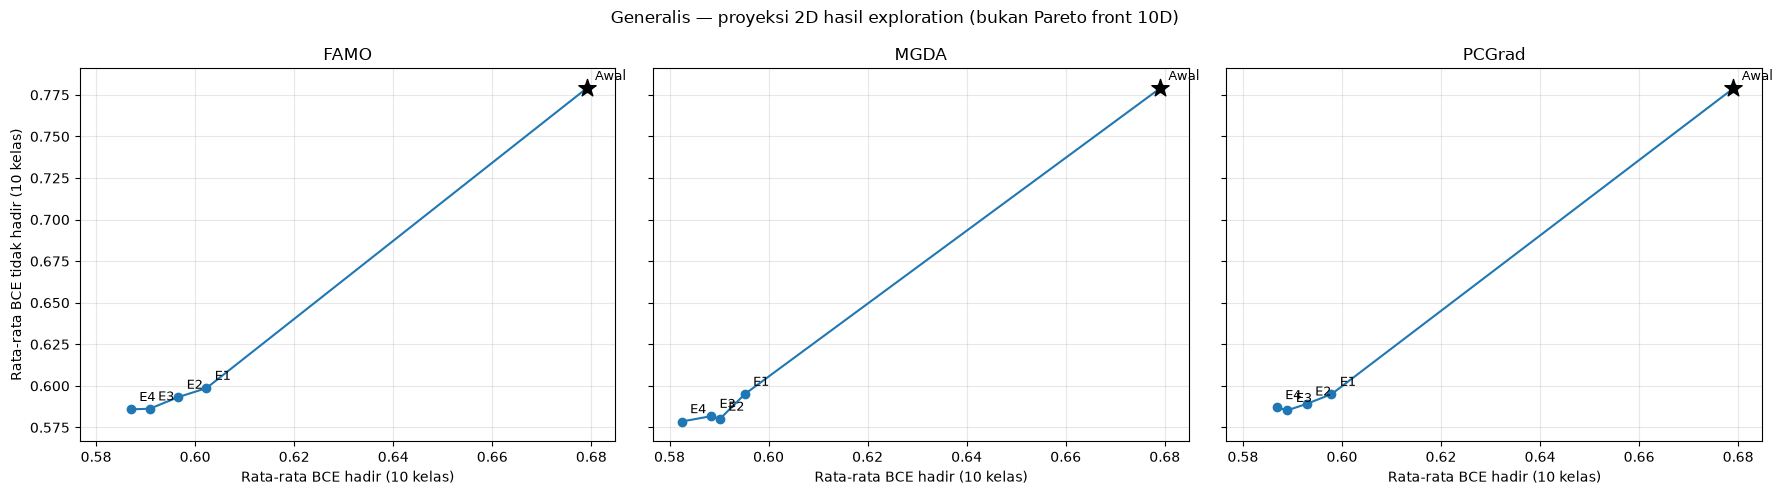

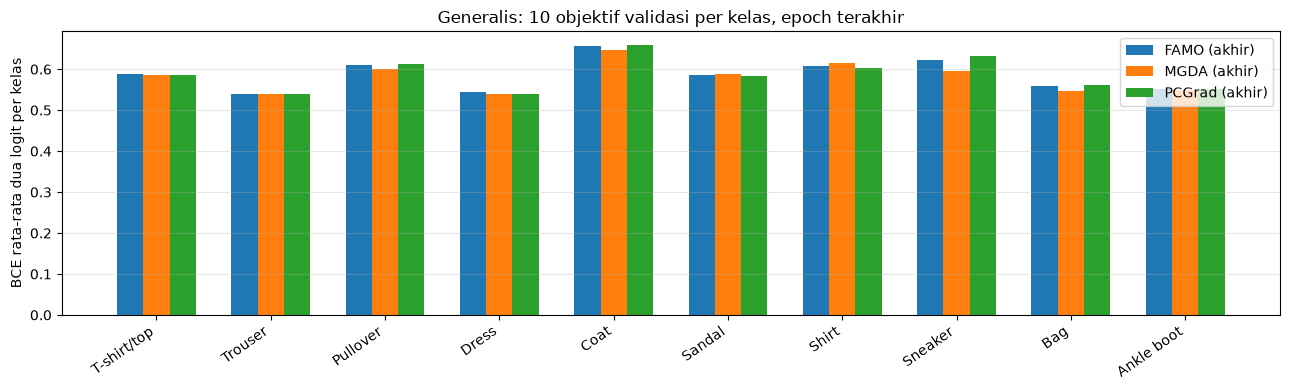

In [ ]:
# Perbandingan apple-to-apple: 3 panel skala sama (proyeksi 2D dari 10 objektif).
methods = ('FAMO', 'MGDA', 'PCGrad')
all_xy = np.vstack([
    np.array([cp['xy'] for cp in [gen_start] + gen_paths[m]])
    for m in methods
])
lo, hi = all_xy.min(axis=0), all_xy.max(axis=0)
margin = np.maximum((hi - lo) * 0.06, 1e-4)
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True, sharey=True)
for ax, method in zip(axes, methods):
    points = [gen_start] + gen_paths[method]
    xy = np.array([cp['xy'] for cp in points])
    ax.plot(xy[:, 0], xy[:, 1], 'o-', label=method)
    ax.scatter(*gen_start['xy'], marker='*', color='black', s=170, zorder=5)
    for ep, coordinates in enumerate(xy):
        ax.annotate('Awal' if ep == 0 else f'E{ep}', coordinates,
                    xytext=(6, 6), textcoords='offset points', fontsize=9)
    ax.set(xlim=(lo[0]-margin[0], hi[0]+margin[0]),
           ylim=(lo[1]-margin[1], hi[1]+margin[1]),
           title=method, xlabel='Rata-rata BCE hadir (10 kelas)')
    ax.grid(alpha=0.3)
axes[0].set_ylabel('Rata-rata BCE tidak hadir (10 kelas)')
fig.suptitle('Generalis — proyeksi 2D hasil exploration (bukan Pareto front 10D)')
plt.tight_layout()
plt.show()

# Tampilkan tujuan yang *benar-benar* dioptimasi: loss per kelas, 10 dimensi.
fig, ax = plt.subplots(figsize=(13, 4))
xx = np.arange(len(CLASS_NAMES))
width = 0.23
for shift, method in zip((-1, 0, 1), methods):
    ax.bar(xx + shift * width, gen_paths[method][-1]['objectives'],
           width=width, label=f'{method} (akhir)')
ax.set_xticks(xx, CLASS_NAMES, rotation=35, ha='right')
ax.set(ylabel='BCE rata-rata dua logit per kelas',
       title='Generalis: 10 objektif validasi per kelas, epoch terakhir')
ax.grid(axis='y', alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()


In [ ]:

def choose_pair_generalist(points, allow_fallback=True):
    """
    Generalist:
    A = minimum BCE hadir pada proyeksi 2D.
    B = minimum BCE tidak hadir pada proyeksi 2D.

    Generalist tetap mempunyai 10 objective asli.
    Pemilihan ini berdasarkan dua sumbu grafik,
    bukan berdasarkan Pareto front 10D.
    """

    eligible = []

    for p in points:
        xy = np.asarray(
            p.get('xy', []), dtype=float
        )
        obj = np.asarray(
            p.get('objectives', []), dtype=float
        )

        if xy.shape != (2,) or not np.isfinite(xy).all():
            continue

        if (
            obj.shape != (len(CLASS_NAMES),)
            or not np.isfinite(obj).all()
        ):
            continue

        if p.get('alpha') is None:
            continue

        alpha_eff = alpha_for_comparison(p)

        if (
            alpha_eff is None
            or len(alpha_eff) != len(CLASS_NAMES)
        ):
            continue

        eligible.append(p)

    if len(eligible) < 2:
        return (
            None,
            'Kurang dari dua checkpoint dengan alpha 10D'
        )

    # Cari minimum loss pada kedua sumbu
    l1_min = min(
        float(p['xy'][0]) for p in eligible
    )
    l2_min = min(
        float(p['xy'][1]) for p in eligible
    )

    # Kandidat A: minimum L1
    a_choices = sorted(
        (
            p for p in eligible
            if float(p['xy'][0]) == l1_min
        ),
        key=lambda p: float(p['xy'][1])
    )

    # Kandidat B: minimum L2
    b_choices = sorted(
        (
            p for p in eligible
            if float(p['xy'][1]) == l2_min
        ),
        key=lambda p: float(p['xy'][0])
    )

    # Harus dua checkpoint berbeda
    for a in a_choices:
        for b in b_choices:
            if a is not b:
                return (
                    (a, b),
                    'A=min BCE hadir; B=min BCE tidak hadir '
                    '(proyeksi 2D)'
                )

    return (
        None,
        'Minimum kedua sumbu hanya dicapai '
        'checkpoint yang sama'
    )



gen_pool = [p for path in gen_paths.values() for p in path]
gen_pair, gen_pair_type = choose_pair_generalist(gen_pool, allow_fallback=True)
print('Pasangan generalis:',
      [p['name'] for p in gen_pair] if gen_pair else None,
      '|', gen_pair_type)


Pasangan generalis: ['FAMO', 'MGDA'] | front kandidat 10D: FAMO–MGDA (trade-off)


In [ ]:
# Expansion Generalist memakai vektor alpha 10D dan objective 10D.
gen_results = {'Tanpa expand': ([], 0., 'Baseline')}
for name, generate in [('MINRES', minres_candidate),
                       ('Alfa tengah', midpoint_candidate),
                       ('Alfa tengah + MGDA', midpoint_mgda_candidate),
                       ('Alfa tengah + FAMO', midpoint_famo_candidate),
                       ('Alfa tengah efektif FAMO-MGDA + MGDA', midpoint_effective_mgda_candidate)]:
    print(f'[Generalis] Expansion {name} ...', flush=True)
    gen_results[name] = run_expand(
        gen_pair, generate, gen_initial, gen_pool,
        gen_train, gen_valid, class_id=None,
    )
    extra, seconds, reason = gen_results[name]
    print(f'  {name}: {len(extra)} kandidat | {seconds:.1f}s | {reason}', flush=True)

# Periksa front dalam ruang objective 10D, bukan proyeksi 2D.
gen_all_points = gen_pool + [p for extra, _, _ in gen_results.values() for p in extra]
gen_pareto_front = [p for p in gen_all_points
                    if not any(dominates(q, p) for q in gen_all_points if q is not p)]
for name, (extra, _, _) in gen_results.items():
    if name != 'Tanpa expand':
        front_count = sum(any(p is q for q in gen_pareto_front) for p in extra)
        print(f'[Generalis] {name}: {front_count}/{len(extra)} di front')


[Generalis] Expansion MINRES ...
MINRES status: 24 | residu relatif: 0.1301
MINRES status: 0 | residu relatif: 0.0655
MINRES status: 0 | residu relatif: 0.0463
  MINRES: 3 kandidat | 0.5s | Skor belum membaik
[Generalis] Expansion Alfa tengah ...
  Alfa tengah: 3 kandidat | 0.7s | Skor belum membaik
[Generalis] Expansion Alfa tengah + MGDA ...
  Alfa tengah + MGDA: 3 kandidat | 6.0s | Skor belum membaik
[Generalis] Expansion Alfa tengah + FAMO ...
  Alfa tengah + FAMO: 3 kandidat | 1.8s | Skor belum membaik
[Generalis] Expansion Alfa tengah efektif FAMO-MGDA + MGDA ...
  Alfa tengah efektif FAMO-MGDA + MGDA: 3 kandidat | 6.1s | Skor belum membaik
[Generalis] MINRES: 1/3 di front
[Generalis] Alfa tengah: 3/3 di front
[Generalis] Alfa tengah + MGDA: 3/3 di front
[Generalis] Alfa tengah + FAMO: 3/3 di front
[Generalis] Alfa tengah efektif FAMO-MGDA + MGDA: 3/3 di front


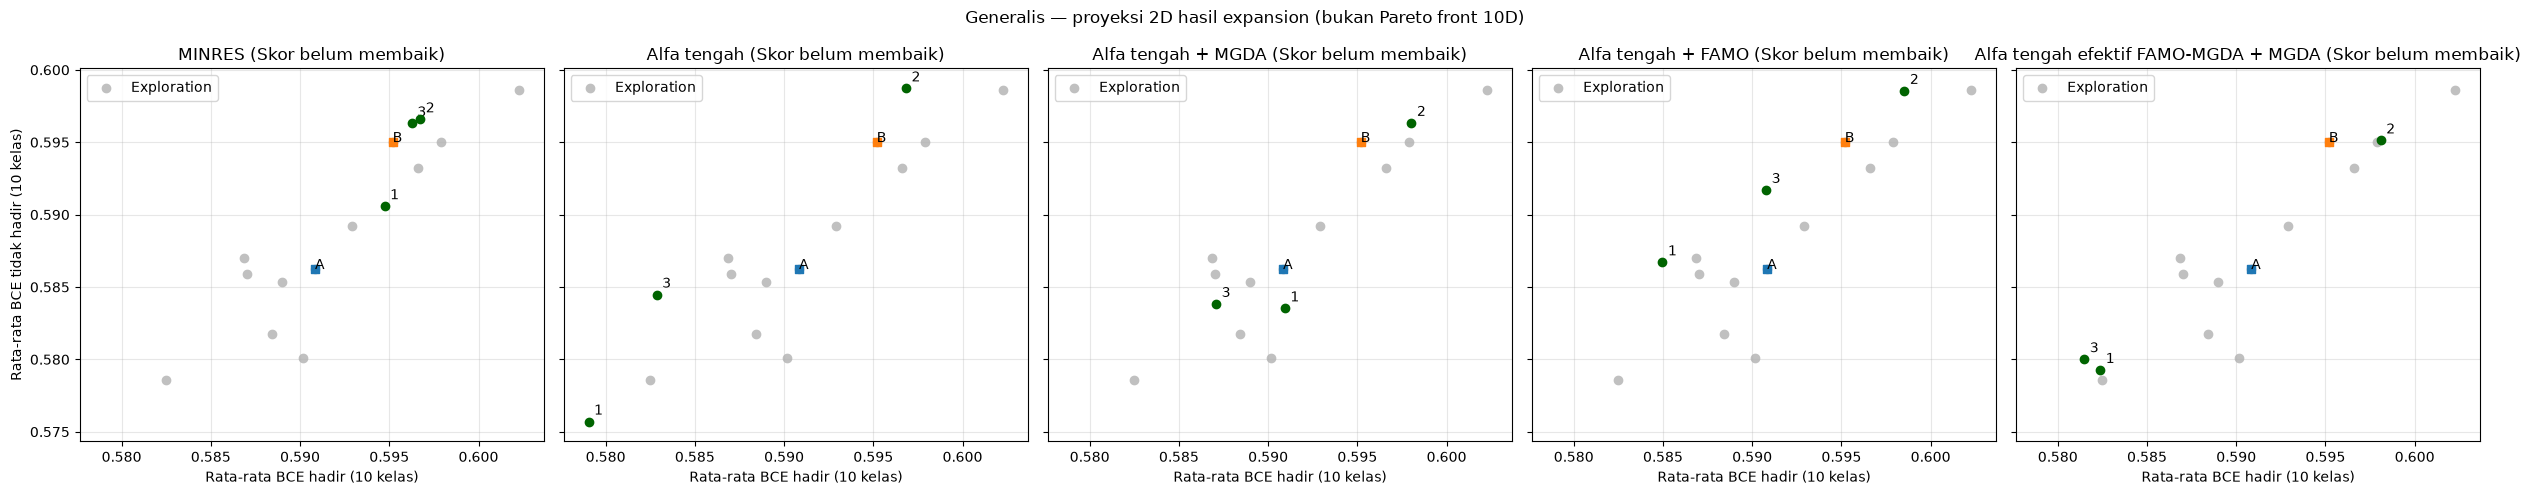

In [ ]:
# Expansion pada proyeksi 2D; kedua panel menggunakan skala X dan Y sama.
all_points = gen_pool + [p for extra, _, _ in gen_results.values() for p in extra]
all_xy = np.array([p['xy'] for p in all_points])
lo, hi = all_xy.min(axis=0), all_xy.max(axis=0)
margin = np.maximum((hi - lo) * 0.06, 1e-4)
names = [name for name in gen_results if name != 'Tanpa expand']
fig, panels = plt.subplots(1, len(names), figsize=(5 * len(names), 5),
                          sharex=True, sharey=True)
panels = np.atleast_1d(panels)
for ax, name in zip(panels, names):
    ax.scatter(*np.array([p['xy'] for p in gen_pool]).T,
               color='silver', label='Exploration')
    if gen_pair is not None:
        for label, point in zip(('A', 'B'), gen_pair):
            ax.scatter(*point['xy'], marker='s', zorder=3)
            ax.annotate(label, point['xy'])
    for r, point in enumerate(gen_results[name][0], 1):
        ax.scatter(*point['xy'], color='darkgreen', zorder=4)
        ax.annotate(str(r), point['xy'], xytext=(4, 5), textcoords='offset points')
    ax.set(title=f'{name} ({gen_results[name][2]})',
           xlim=(lo[0]-margin[0], hi[0]+margin[0]),
           ylim=(lo[1]-margin[1], hi[1]+margin[1]),
           xlabel='Rata-rata BCE hadir (10 kelas)')
    ax.grid(alpha=0.3)
    ax.legend()
panels[0].set_ylabel('Rata-rata BCE tidak hadir (10 kelas)')
fig.suptitle('Generalis — proyeksi 2D hasil expansion (bukan Pareto front 10D)')
plt.tight_layout()
plt.show()



GENERALIST — MULTILABEL 10 KELAS
Metode                                                Status            Acc test      Prec    Recall        F1       AUC
Tanpa exploration/expansion                           ok                  0.7308    0.4573    0.0494    0.0892    0.5986
Exploration terbaik                                   ok                  0.7296    0.4680    0.1008    0.1659    0.6433
Exploration PCGrad                                    ok                  0.7319    0.4723    0.0435    0.0797    0.6069
Exploration MGDA                                      ok                  0.7296    0.4680    0.1008    0.1659    0.6433
Exploration FAMO                                      ok                  0.7307    0.4769    0.1014    0.1672    0.6407
Expansion MINRES                                      ok                  0.7333    0.3333    0.0001    0.0001    0.5726
Expansion Alfa tengah                                 ok                  0.7342    0.5114    0.0755    0.1316    0.639

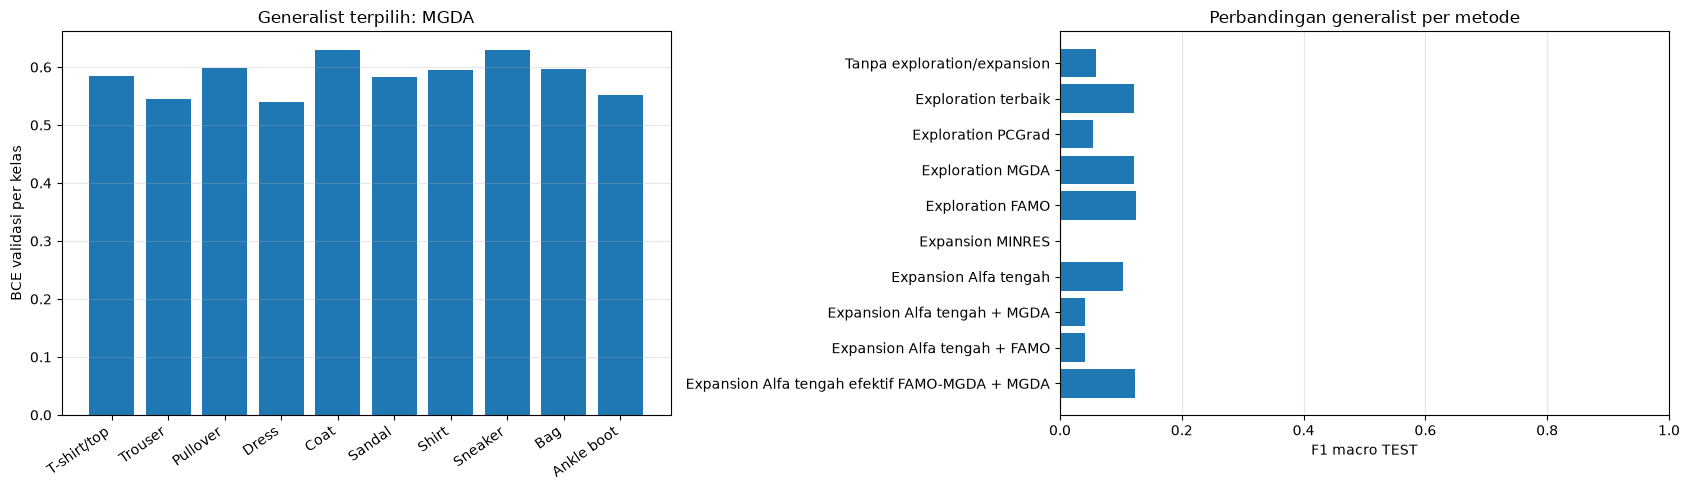

In [ ]:
# Evaluasi semua skenario generalist berdasarkan checkpoint validasi masing-masing.
all_gen_candidates = gen_pool + [p for extra, _, _ in gen_results.values() for p in extra]
gen_groups = [('Tanpa exploration/expansion', gen_baseline_paths, 'Baseline'),
              ('Exploration terbaik', gen_pool, 'Exploration')]
gen_groups += [(f'Exploration {method}', gen_paths[method], 'Exploration')
               for method in ('PCGrad', 'MGDA', 'FAMO')]
gen_groups += [(f'Expansion {name}', extra, 'Expansion')
               for name, (extra, _, _) in gen_results.items() if name != 'Tanpa expand']
gen_comparison = evaluate_method_groups(
    gen_initial, gen_groups, gen_valid, gen_test, class_id=None,
    unavailable_reasons={f'Expansion {name}': reason
                         for name, (_, _, reason) in gen_results.items()}
)
print_comparison(gen_comparison, title='GENERALIST — MULTILABEL 10 KELAS')
save_metrics_reports('generalist', gen_comparison)

# Tabel khusus setiap kelas Generalist (untuk setiap metode × split).
import csv
from pathlib import Path
output_folder = Path(CFG['REPORT_DIR'])
per_class_path = output_folder / 'generalist_metrics_per_class.csv'
per_class_rows = []
for row in gen_comparison:
    for split in ('valid', 'test'):
        details = row.get(f'{split}_per_class', [])
        for detail in details:
            per_class_rows.append(dict(method=row['method'], stage=row['stage'],
                                       status=row['status'], split=split, **detail))
if per_class_rows:
    with per_class_path.open('w', encoding='utf-8-sig', newline='') as handle:
        writer = csv.DictWriter(handle, fieldnames=list(per_class_rows[0].keys()))
        writer.writeheader()
        writer.writerows(per_class_rows)
    print('Laporan per kelas generalist:', per_class_path)

# Pemenang tetap berdasarkan 10 objective validasi, tidak melihat metrik test.
gen_winner = min(all_gen_candidates, key=lambda p: p['score'])
gen_best_model = deepcopy(gen_initial)
gen_best_model.load_state_dict(gen_winner['state'])
gen_best_model.eval()
gen_test_objectives, gen_test_xy = evaluate(
    gen_best_model, gen_test, return_components=True
)
print('\nGENERALIS TERPILIH:', gen_winner['name'])
print('Validasi 10 objektif:', np.round(gen_winner['objectives'], 4))
print('Validasi minimax 10 kelas:', round(gen_winner['score'], 5))
print('Test 10 objektif:', np.round(gen_test_objectives, 4))
print('Test proyeksi hadir/tidak:', np.round(gen_test_xy, 4))

if CFG['SAVE_TEACHERS']:
    output_path = Path(CFG['TEACHER_DIR']) / 'generalist_best.pt'
    output_path.parent.mkdir(parents=True, exist_ok=True)
    torch.save({
        'architecture': 'Generalist-CNN-10heads',
        'selected_method': gen_winner['name'],
        'valid_objectives': gen_winner['objectives'].tolist(),
        'valid_projection_xy': gen_winner['xy'].tolist(),
        'score': gen_winner['score'],
        'alpha': None if gen_winner['alpha'] is None else gen_winner['alpha'].tolist(),
        'alpha_effective': None if alpha_for_comparison(gen_winner) is None
                           else alpha_for_comparison(gen_winner).tolist(),
        'state_dict': gen_winner['state'],
    }, output_path)
    print('Model Generalist disimpan:', output_path)

fig, axes = plt.subplots(1, 2, figsize=(17, 5))
axes[0].bar(np.arange(len(CLASS_NAMES)), gen_winner['objectives'])
axes[0].set_xticks(np.arange(len(CLASS_NAMES)), CLASS_NAMES, rotation=35, ha='right')
axes[0].set(title=f'Generalist terpilih: {gen_winner["name"]}', ylabel='BCE validasi per kelas')
axes[0].grid(axis='y', alpha=0.3)
shown = [r for r in gen_comparison if r['status'] == 'ok']
axes[1].barh([r['method'] for r in shown], [r['test_f1_macro'] for r in shown])
axes[1].invert_yaxis()
axes[1].set(xlim=(0, 1), xlabel='F1 macro TEST', title='Perbandingan generalist per metode')
axes[1].grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()


## Definisi metrik, interpretasi dan reproduksibilitas

- **Specialist**: klasifikasi biner `kelas c hadir` vs `bukan kelas c`, prediksi dari `sigmoid(logit_hadir) >= 0.5`. Accuracy, precision, recall/sensitivity, specificity, F1, balanced accuracy, ROC-AUC, average precision (AP), serta confusion matrix dilaporkan per metode untuk train-independent **valid dan test**. Head tidak-hadir dipakai saat menghitung BCE multiobjektif, tetapi evaluasi biner mengukur head hadir yang dipakai teacher.
- **Generalist**: klasifikasi **multilabel**, bukan single-label softmax. `sigmoid(logits[:, :, 0]) >= 0.5` terhadap label multi-hot yang asli, dengan accuracy Hamming (persentase label benar) dan exact-match accuracy (semua 10 label pada gambar benar), precision/recall/F1 micro, macro, weighted, dan per kelas, ROC-AUC serta AP per kelas. Semua metrik dihitung pada data validasi dan test (bukan target teacher soft di train).
- **Pemilihan**: tiap metode memilih checkpoint dengan minimax BCE pada **validasi saja**; test hanya dilihat sesudah seleksi. `Exploration terbaik` membandingkan checkpoint PCGrad, MGDA, dan FAMO, tanpa expansion. Baris expansion kosong tetap ditandai `tidak tersedia`.
- **FAMO mentah vs efektif**: `alpha` menyimpan `softmax(w)` untuk ablation legacy; `alpha_effective` menyimpan koefisien gradien (normalisasi `softmax(w)/(loss+eps)`), dihitung pada setiap minibatch sebelum step, lalu dirata-ratakan dalam jendela akhir epoch. MGDA mengeluarkan koefisien gradien langsung. `midpoint_effective_mgda_candidate` menggunakan keduanya untuk midpoint lalu Pareto exploration MGDA dari model midpoint. Ini perbandingan *semantik koefisien* apple-to-apple, bukan pemerataan kualitas estimasi stochastic, dan tidak menjamin true Pareto front.
- **Fairness**: baseline, PCGrad, MGDA, FAMO dimulai dari bobot awal, LR, BS, dan jumlah epoch sama. Metode expansion memperoleh langkah optimasi tambahan (`STEPS` + `MIDPOINT_REFINE_STEPS`), sehingga perbandingan bukan *compute-matched*. Perbandingan F1 test bersifat deskriptif; validasi adalah kriteria model-selection agar terhindar kebocoran test.
- **Laporan**: `fashion_cnn_reports/specialists_metrics.csv`, `specialists_metrics.json`, `generalist_metrics.csv`, `generalist_metrics.json`, `generalist_metrics_per_class.csv` muncul sesudah training notebook selesai. Hasil numerik **belum tersedia** sebelum menjalankan training.
- **Batasan**: model tetap CNN sederhana, bukan ResNet. Skor Pareto generalist adalah 10 loss, grafik 2D hanya proyeksi. Jika hanya satu kelas label pada suatu split, ROC-AUC tidak didefinisikan (ditulis `NaN`). Memakai dataset Fashion-MNIST yang diunduh pada pemakaian pertama.
